# Project 2: Numerical Methods
This project aims to identify the most accurate numerical integration method for a damped mass-spring system.

Date: 5 of April 2024

#### Revision (October 2026)
The notebook was corrected after a review. The changes and their effect on the results:

1. **Common time grid.** The SciPy Runge-Kutta results were output on `linspace(0, nsteps*h, nsteps)`, a spacing of $nh/(n-1)$ instead of $h$, while the analytical solution used `arange(0, T, h)`. This roughly doubled the reported Runge-Kutta error and made Euler-Cromer appear best for $b=0.1$ kg/s. All methods and analytical solutions now share one grid $t_i = ih$ (function `time_grid`).
2. **Fixed-step Runge-Kutta 4 added.** The "Runge-Kutta" method was SciPy's adaptive RK45 with default tolerances, whose error does not depend on $h$. A classical RK4 with step $h$ was added; RK45 is kept as `RK45 (scipy)`.
3. **Verlet is now second order.** The previous version used the velocity from one step earlier in the damping force, which made it first order. It is replaced by velocity Verlet with the damping term treated implicitly.
4. **Analytical energy.** `total_energy_analytical` had the wrong sign on one term of the velocity, so the analytical energy curves were wrong. This was the cause of the "out of phase" differences noted in the energy section.
5. **Critical damping** is detected with a tolerance instead of `b == b_cr` (function `analytic_solution`).
6. **Driven motion** is compared with its exact analytical solution (new section), not only with the unforced motion. The RK45 solver for the driven system uses tight tolerances, and a maximum step so it cannot step over the sudden force.
7. **Resonance curve** uses the steady-state amplitude (after transients have decayed) and is compared with the analytical amplitude, instead of the largest $|x|$ over a run that includes the start-up transient.
8. **Error against step size** is plotted on log-log axes, where the slope is the order of accuracy of each method.
9. Corrected formulas in the text (Verlet, Euler-Cromer, $\omega_d$, the order of Improved Euler) and the unit of MSE (m²). The observation notes and the conclusion were rewritten for the corrected results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cmath
from scipy.integrate import solve_ivp

plt.rcParams.update({'font.size': 16})
plt.style.use('default')

### Damped Mass-Spring System

A damped mass-spring system consists of a mass attached to a spring and a damper. The system's dynamics are governed by a second-order differential equation that accounts for the spring's restoring force, the damper's resistance (which opposes velocity), and any external forces applied to the mass. The equation typically takes the form

$$m \ddot{x}+b \dot{x}+kx=F(t)$$

where $m$ is the mass, $b$ is the damping coefficient, $k$ is the spring constant, $x$ is the displacement, and $F(t)$ represents the time-dependent external force.

#### Applied Force Variants
##### Sudden Force:
A sudden force acts for a short time, abruptly changing the system's motion. An ideal impulse is a Dirac delta function; here it is modelled as a constant force applied for a short duration (a rectangular pulse), which lets us study the system's transient response.

#####  Sinusoidal Force:
A sinusoidal force varies cyclically over time, modeled as
$$F(t) = F_0 \cos{(\omega t + \phi)}$$

where, $F_0$ is the amplitude, $\omega$ is the angular frequency, and $\phi$ is the phase. This type of force is used to examine the system's steady-state oscillatory response and to study phenomena such as resonance, where the system's natural frequency aligns with the frequency of the external force, often leading to significant increases in amplitude.

### Constants and Initial Conditions

In this sysem we will use following constant values. Additionally we use the range of values of low damping coefficients, time step size and total time taken for broader view of the system and more accurate analysis.

In [2]:
# Physics parameters
m = 5.58  # mass in kg
k = 1.81  # spring constant in kg/s^2

# Initial conditions
x0 = 0  # initial position in m
v0 = -1.0  # initial velocity in m/s

# Damping coefficient, Total Time, Time steps h
b = [0.1, 0.5, 2.0]  # damping coefficient in kg/s
T = [50.0, 150.0, 300]  # Total time
h = [0.1, 0.05, 0.01]  # Time step sizes in sec

### Analytical Solutions:
Analytical solutions provides guidance of what we should expect from the system. It allows us to compare different numerical methods of integration in order to determine best method.
#### Low Damping:
The solution that applies to the underdamped systems is given as
$$ x(t) =e^{\frac{-bt}{2m}}\left(Ae^{i\omega_d t}+ Be^{-i\omega_d t}\right) $$

where

$$\omega_d = \frac{\sqrt{4km-b^2}}{2m}$$

$$A=\left(\frac{b}{2i\sqrt{4km-b^2}}+\frac{1}{2}\right)x_0 +\frac{v_0 m}{\sqrt{4km-b^2}\,i}$$
$$B = x_0-A$$
#### Critical Damping:
The solution that applies to the critically damped systems is given as
$$ x(t) = (A+Bt)e^{\frac{-bt}{2m}}$$

where

$$A= x_0$$
$$B= v_0 + \frac{b}{2m}x_0$$
#### Heavy Damping:
The solution that applies to the heavily damped systems is given as
$$x(t) = Ae^{\lambda_1 t}+Be^{\lambda_2 t}$$

where

$$\lambda_1 = \frac{-b}{2m}+r$$
$$\lambda_2 = \frac{-b}{2m}-r$$
$$r = \sqrt{\frac{b^2}{4m^2}-\frac{k}{m}}$$
$$A = x_0 -B$$
$$B = \frac{v_0 - \lambda_1 x_0}{\lambda_2- \lambda_1}$$

The function `analytic_solution` picks the right expression for a given $b$. Because $b$ is a floating-point number, critical damping is detected with a small relative tolerance rather than an exact comparison.

In [3]:
# The analytic solution when b is less than b_cr
def Analytic(x0, v0, time, b):
    """
    Analytical solution for underdamped mass-spring system.
    """
    # Constants
    A = (b/(2*1j*cmath.sqrt(4*k*m-b**2))+1/2)*x0+v0*m/(cmath.sqrt(4*k*m-b**2)*1j)
    B = x0-A

    X = np.exp(-b*time/(2*m))*(A*np.exp(1j*cmath.sqrt(4*k*m-b**2)*time/(2*m))
                              +B*np.exp(-1j*cmath.sqrt(4*k*m-b**2)*time/(2*m)))

    return X

def AnalyticCritical(x0, v0, time, b):
    """
    Analytical solution for a critically damped mass-spring system.
    """
    # Calculate A and B based on initial conditions
    A = x0
    B = v0 + (b * x0) / (2 * m)

    # Solution for critical damping
    X = (A + B * time) * np.exp(-b * time / (2 * m))
    return X

def AnalyticOverdamped(x0, v0, time, b):
    """
    Analytical solution for an overdamped mass-spring system.
    """
    # Calculate roots of characteristic equation
    r = np.sqrt(b**2 - 4 * k * m) / (2 * m)

    lambda_1 = -b / (2 * m) + r
    lambda_2 = -b / (2 * m) - r

    # Calculate A and B based on initial conditions
    # Using the system of equations: x0 = A + B, v0 = lambda_1*A + lambda_2*B
    B = (v0 - lambda_1 * x0) / (lambda_2 - lambda_1)
    A = x0 - B

    # Solution for overdamping
    X = A * np.exp(lambda_1 * time) + B * np.exp(lambda_2 * time)
    return X

def analytic_solution(x0, v0, time, b):
    """
    Analytical position for any damping coefficient. Critical damping is detected with a
    tolerance rather than b == b_cr, because b is a floating-point number.
    """
    b_cr = 2 * np.sqrt(k * m)
    if np.isclose(b, b_cr, rtol=1e-9, atol=0):
        return AnalyticCritical(x0, v0, time, b)
    if b < b_cr:
        return Analytic(x0, v0, time, b).real
    return AnalyticOverdamped(x0, v0, time, b)

### Functions - Numerical Methods of Integration

This experiment investigates 6 methods of numerical integration: Euler's, Improved Euler's, Verlet's, Euler-Cromer's, Runge-Kutta of order 4 with a fixed step, and SciPy's adaptive Runge-Kutta 45 (an alternative that is easier to use but does not use the step size $h$). All methods are evaluated on the same time grid $t_i = ih$ as the analytical solutions.

Below, $a_i = -(k/m) x_i - (b/m) v_i$ is the acceleration. The *global* error is the error after integrating up to a fixed time; a method with local (one-step) error $O(h^{p+1})$ has global error $O(h^p)$ and is called order $p$.

#### Euler Method:

$$x_{i+1} = x_{i} + h \cdot v_{i}$$
$$v_{i+1} = v_{i} + h \cdot a_{i}$$

with global error $O(h)$.

#### Improved Euler Method:
This method adds the next term of the Taylor expansion to the position update

$$x_{i+1} = x_{i} + h \cdot v_{i} + \frac{h^2}{2}a_i$$
$$v_{i+1} = v_{i} + h \cdot a_{i}$$

The velocity update is still Euler's, so the global error remains $O(h)$. (Heun's method, which also corrects the velocity, would be second order.)

#### Verlet's Method:
Expanding $x(t+h)$ and $x(t-h)$ in Taylor series and adding them gives the position Verlet scheme $x_{i+1} = 2x_{i} - x_{i-1} + h^2a_i$. Because the damping force depends on the velocity, we use the equivalent *velocity Verlet* form, which also gives the velocity at every step and needs no special first step:

$$v_{i+1/2} = v_i + \frac{h}{2} a_i$$
$$x_{i+1} = x_i + h\, v_{i+1/2}$$
$$v_{i+1} = v_{i+1/2} + \frac{h}{2} a_{i+1}, \qquad a_{i+1} = -\frac{k}{m}x_{i+1} - \frac{b}{m}v_{i+1}$$

The last equation contains $v_{i+1}$ on both sides; it is linear, so it is solved directly: $v_{i+1} = \left(v_{i+1/2} - \frac{hk}{2m}x_{i+1}\right) / \left(1 + \frac{hb}{2m}\right)$. The global error is $O(h^2)$.

#### Euler-Cromer's Method:
It is another adjusted Euler's Method which is a type of Symplectic Integrator: without damping its energy oscillates about the true value instead of drifting. The velocity is updated first and the new velocity is used for the position:

$$v_{i+1} = v_{i} + h\, a_i = v_i - \frac{h}{m}\left(k x_i + b v_i\right)$$
$$x_{i+1} = x_{i} + h \cdot v_{i+1}$$

with global error $O(h)$.

#### Runge-Kutta 4 Method:
The Runge-Kutta 4th order method (RK4) solves the second-order equation as the first-order system $y = (x, v)$, $f(t, y) = (v, a)$. It calculates intermediate slopes over a single timestep:

$$k_1 = hf(t_i, y_i)$$
$$k_2 = hf(t_i+h/2, y_i +k_1/2)$$
$$k_3 = hf(t_i+h/2, y_i+k_2/2)$$
$$k_4 = hf(t_i+h,y_i+k_3)$$

The solution is then updated using:

$$y_{i+1}=y_i+\frac{1}{6}(k_1+2k_2+2k_3+k_4)$$

with global error $O(h^4)$.

#### Runge-Kutta 45 (SciPy):
`scipy.integrate.solve_ivp` with `method='RK45'` uses an adaptive Runge-Kutta pair of orders 4 and 5: it chooses its own step sizes so that the estimated error stays within the relative and absolute tolerances (by default $10^{-3}$ and $10^{-6}$). The step size $h$ only sets the times at which the solution is reported, so its accuracy does not improve when $h$ is reduced.

In [4]:
# The method implementation of Euler's Method
def EulerMethod(x0, v0, nsteps, hstep, b):
    """
    Numerical Method: Euler's
    """
    # Create empty arrays ready for the values of x and v
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    energy = np.zeros(nsteps)

    # Assign initial conditions
    x[0] = x0
    v[0] = v0
    energy[0] = 0.5 * m * v0**2 + 0.5 * k * x0**2

    for i in range(nsteps-1):

        # Calculate the acceleration at step i (in m/s^2)
        a = -(k/m)*x[i] - (b/m)*v[i]
        # For each configuration at step i, calculate x (in m) and v (in m/s) for the later step i+1
        x[i+1] = x[i] + v[i]*hstep
        v[i+1] = v[i] + a*hstep
        # Calculate energy at each step
        energy[i+1] = 0.5 * m * v[i+1]**2 + 0.5 * k * x[i+1]**2

    return x, v, energy

# The method implementation of Improved Euler's Method
def ImprovedEuler(x0, v0, nsteps, hstep, b):
    """
    Numerical Method: Improved Euler's
    """
    # Create empty arrays ready for the values of x and v
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    energy = np.zeros(nsteps)

    # Assign initial conditions
    x[0] = x0
    v[0] = v0
    energy[0] = 0.5 * m * v0**2 + 0.5 * k * x0**2

    for i in range(nsteps-1):
        # Calculate the acceleration at step i (in m/s^2)
        a = -(k/m)*x[i] - (b/m)*v[i]
        # Improved Euler method adjustment
        x[i+1] = x[i] + v[i]*hstep + (hstep**2 / 2) * a
        v[i+1] = v[i] + a*hstep
        # Calculate energy at each step
        energy[i+1] = 0.5 * m * v[i+1]**2 + 0.5 * k * x[i+1]**2

    return x, v, energy

def VerletMethod(x0, v0, nsteps, hstep, b):
    """
    Numerical Method: Verlet's (velocity Verlet).

    The damping force depends on the velocity, so it is evaluated at the end of the step and the
    velocity update is solved for v[i+1] (the equation is linear in v[i+1]). This keeps the method
    second order with damping, and it needs no separate first step.
    """
    # Initialize arrays for positions, velocities, and energies
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    energy = np.zeros(nsteps)

    # Set initial conditions
    x[0], v[0] = x0, v0
    energy[0] = 0.5 * m * v0**2 + 0.5 * k * x0**2
    a = -(k/m) * x0 - (b/m) * v0

    for i in range(nsteps - 1):
        # Half-step velocity, then the full position step
        v_half = v[i] + 0.5 * hstep * a
        x[i+1] = x[i] + hstep * v_half
        # v[i+1] = v_half + (h/2) * a(x[i+1], v[i+1]), solved for v[i+1]
        v[i+1] = (v_half - 0.5 * hstep * (k/m) * x[i+1]) / (1 + 0.5 * hstep * b / m)
        # Acceleration at the new position and velocity, used in the next step
        a = -(k/m) * x[i+1] - (b/m) * v[i+1]
        energy[i+1] = 0.5 * m * v[i+1]**2 + 0.5 * k * x[i+1]**2

    return x, v, energy

# The method implementation of Euler-Cromer's Method
def EulerCromerMethod(x0, v0, nsteps, hstep, b):
    """
    Numerical Method: Euler-Cromer's
    """
    # Create empty arrays ready for the values of x and v
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    energy = np.zeros(nsteps)

    # Assign initial conditions
    x[0] = x0
    v[0] = v0
    energy[0] = 0.5 * m * v0**2 + 0.5 * k * x0**2

    for i in range(1, nsteps):
        # Calculate the acceleration at step i-1
        a = -(b/m) * v[i-1] - (k/m) * x[i-1]
        # Update velocity at step i using the acceleration at step i-1
        v[i] = v[i-1] + hstep * a
        # Update position at step i using the updated velocity at step i
        x[i] = x[i-1] + hstep * v[i]
        # Calculate energy at each step
        energy[i] = 0.5 * m * v[i]**2 + 0.5 * k * x[i]**2

    return x, v, energy

def RungeKutta4(x0, v0, nsteps, hstep, b):
    """
    Numerical Method: classical fixed-step Runge-Kutta of order 4.
    """
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    x[0], v[0] = x0, v0

    def acceleration(x, v):
        return -(k/m) * x - (b/m) * v

    for i in range(nsteps - 1):
        k1x, k1v = v[i], acceleration(x[i], v[i])
        k2x, k2v = v[i] + 0.5*hstep*k1v, acceleration(x[i] + 0.5*hstep*k1x, v[i] + 0.5*hstep*k1v)
        k3x, k3v = v[i] + 0.5*hstep*k2v, acceleration(x[i] + 0.5*hstep*k2x, v[i] + 0.5*hstep*k2v)
        k4x, k4v = v[i] + hstep*k3v, acceleration(x[i] + hstep*k3x, v[i] + hstep*k3v)
        x[i+1] = x[i] + hstep/6 * (k1x + 2*k2x + 2*k3x + k4x)
        v[i+1] = v[i] + hstep/6 * (k1v + 2*k2v + 2*k3v + k4v)

    energy = 0.5 * m * v**2 + 0.5 * k * x**2
    return x, v, energy

# The additional Runge-Kutta method using scipy integration
def RungeKutta(x0, v0, nsteps, hstep, b, rtol=1e-3, atol=1e-6):
    """
    Numerical Method: SciPy's adaptive Runge-Kutta 45.

    The solver chooses its own step sizes to meet rtol/atol (SciPy's defaults unless given),
    so hstep only sets the output times t_i = i*hstep, the same grid as the other methods.
    """
    # Output times: the same grid as every other method
    t_eval = hstep * np.arange(nsteps)
    t_span = [0, t_eval[-1]]

    # Define the ODE system
    def mass_spring_damper_system(t, y):
        x, v = y
        dxdt = v
        dvdt = -(b/m) * v - (k/m) * x
        return [dxdt, dvdt]

    # Initial conditions
    y0 = [x0, v0]

    # Solve the ODE
    sol = solve_ivp(mass_spring_damper_system, t_span, y0, method='RK45', t_eval=t_eval, rtol=rtol, atol=atol)

    # Calculate energy
    energy = 0.5 * m * sol.y[1]**2 + 0.5 * k * sol.y[0]**2

    return sol.t, sol.y[0], sol.y[1], energy  # Returning time, x (displacement), and v (velocity)

def RK45Method(x0, v0, nsteps, hstep, b):
    """
    SciPy RK45 with the same arguments and return values (x, v, energy) as the other methods.
    """
    _, x, v, energy = RungeKutta(x0, v0, nsteps, hstep, b)
    return x, v, energy

# All methods, with a fixed colour for each one in every plot
METHODS = {
    'Euler': EulerMethod,
    'Improved Euler': ImprovedEuler,
    'Verlet': VerletMethod,
    'Euler-Cromer': EulerCromerMethod,
    'Runge-Kutta 4': RungeKutta4,
    'RK45 (scipy)': RK45Method,
}
COLORS = {'Euler': 'blue', 'Improved Euler': 'green', 'Verlet': 'purple', 'Euler-Cromer': 'cyan',
          'Runge-Kutta 4': 'red', 'RK45 (scipy)': 'magenta'}

def time_grid(T, hstep):
    """
    Number of steps and the time grid t_i = i*hstep (0 <= t < T) shared by every method
    and by the analytical solution.
    """
    nsteps = int(round(T / hstep))
    return nsteps, hstep * np.arange(nsteps)

### Investigation of all methods for two different scenarios

##### Scenario 1: Constant step size and varying damping coefficient.

The time step have been chosen the smallest one $h=0.01$ s, so that we can see the effect of varying damping when methods are most efficient. The damping coeffcients are chosen to be $0.1, 0.5, 2.0$ kg/s. Code iterates through all coeffcients for every method and plot the obtained results.

##### Scenario 2: Constant damping coefficient and varying step size.

In this part we will more closely investigate what happens to chosen methods when the time step size is decreasing from $0.1$ s down to $0.05$ s and then $0.01$ s. For this part we assumed damping constant to be $b=0.1$ kg/s. It is chosen to be small so that we can observe effects of different step size for a longer period of time. Results are plotted for visual comparison of each method.

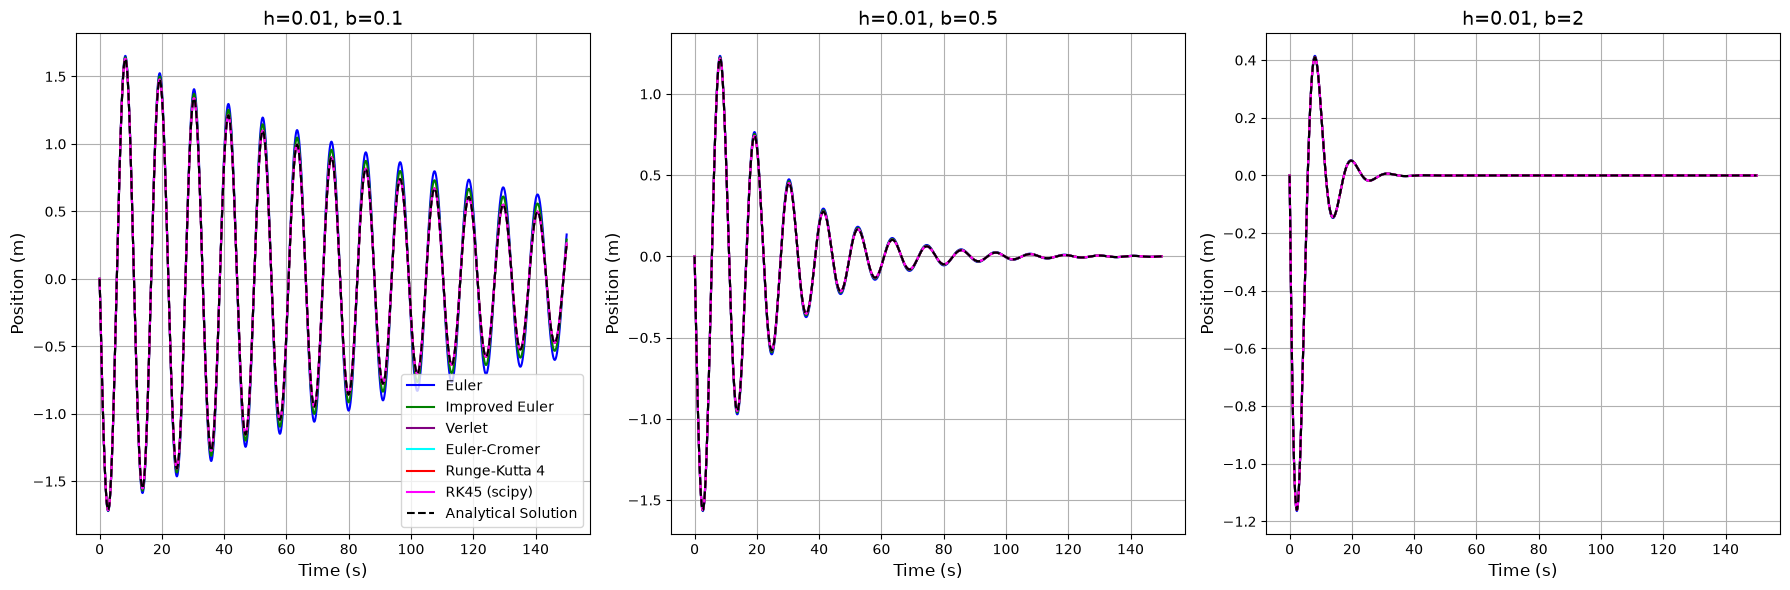

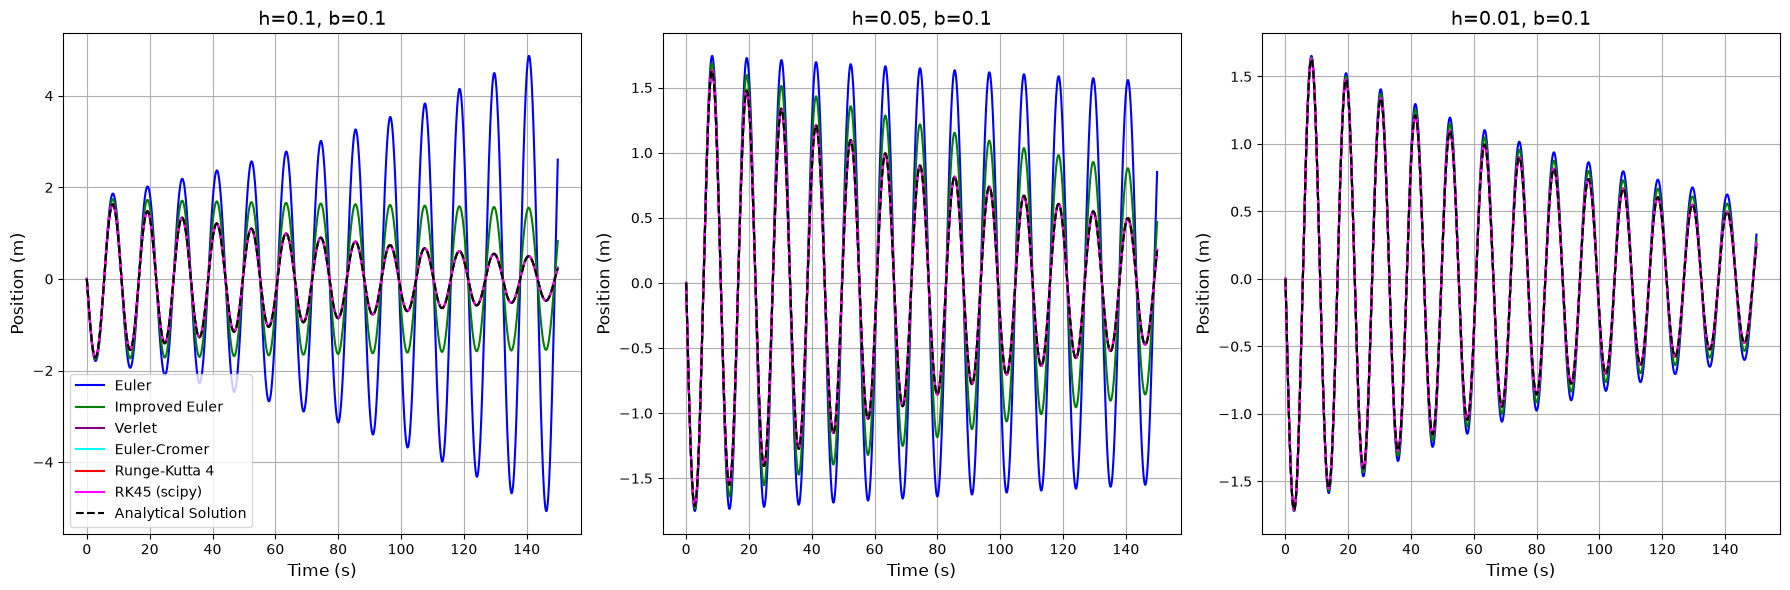

In [5]:
def run_simulation(hstep, b, T, methods=None):
    """
    This function runs the numerical methods and the analytical solution on the same time grid.
    It returns the time grid, the analytical positions and a dictionary {method name: positions}.
    """
    methods = methods or list(METHODS)
    nsteps, t_range = time_grid(T, hstep)
    x_analytic = analytic_solution(x0, v0, t_range, b)
    positions = {name: METHODS[name](x0, v0, nsteps, hstep, b)[0] for name in methods}
    return t_range, x_analytic, positions

def plot_positions(t_range, x_analytic, positions, title, show_legend):
    """
    Plots the position against time for every method, with the analytical solution as a reference.
    """
    for name, x in positions.items():
        plt.plot(t_range, x, label=name, linestyle='-', color=COLORS[name])
    plt.plot(t_range, x_analytic, label='Analytical Solution', linestyle='--', color='black')
    # Title and labels
    plt.title(title, fontsize=14)
    plt.xlabel('Time (s)', fontsize=12)
    plt.ylabel('Position (m)', fontsize=12)
    if show_legend:
        plt.legend(fontsize=10)
    plt.grid(True)

# Scenario 1: constant step size, varying damping coefficient
plt.figure(figsize=(18, 6))
for index, b_val in enumerate(b):
    plt.subplot(1, len(b), index + 1)
    plot_positions(*run_simulation(h[2], b_val, T[1]), f'h={h[2]}, b={b_val:.3g}', index == 0)
plt.tight_layout()
plt.show()

# Scenario 2: constant damping coefficient, varying step size
plt.figure(figsize=(18, 6))
for index, hstep in enumerate(h):
    plt.subplot(1, len(h), index + 1)
    plot_positions(*run_simulation(hstep, b[0], T[1]), f'h={hstep}, b={b[0]:.3g}', index == 0)
plt.tight_layout()
plt.show()

### Observation Notes 1

##### Scenario 1:
The differences are very small at $h=0.01$ s. For the smallest damping coefficient $b=0.1$ kg/s, Euler's method deviates the most from the analytical curve, followed by Improved Euler. As the damping increases all methods match the analytical curve closely on this scale.

##### Scenario 2:
Euler's method is clearly the worst. For the largest time step $h=0.1$ s its amplitude grows with time, which contradicts the loss of energy through damping, so it does not make physical sense; Improved Euler shows the same effect to a lesser degree. Verlet's, Euler-Cromer's and both Runge-Kutta methods reproduce the analytical solution closely for every step size. The next sections quantify these differences.

### Further investigation of methods accuracy using difference between numerical integration method and analytical solution

To clearly show the differences between various numerical methods, an analysis can be conducted by looking at how much each method's results differ from the analytical solution. Ideally, this difference would be zero for every point along the curve, indicating a perfect match between the numerical and analytical solutions. Therefore, any significant deviation from zero on the y-axis would suggest inaccuracies in the numerical approximation. This investigation will be divided into two main parts: the first will examine the impact of changing step sizes while keeping a constant, low damping coefficient; the second will look at the effects of varying damping coefficients around critical values, with a constant step size. This approach will help identify the most effective method under specific system characteristics and highlight the strengths and weaknesses of each method.

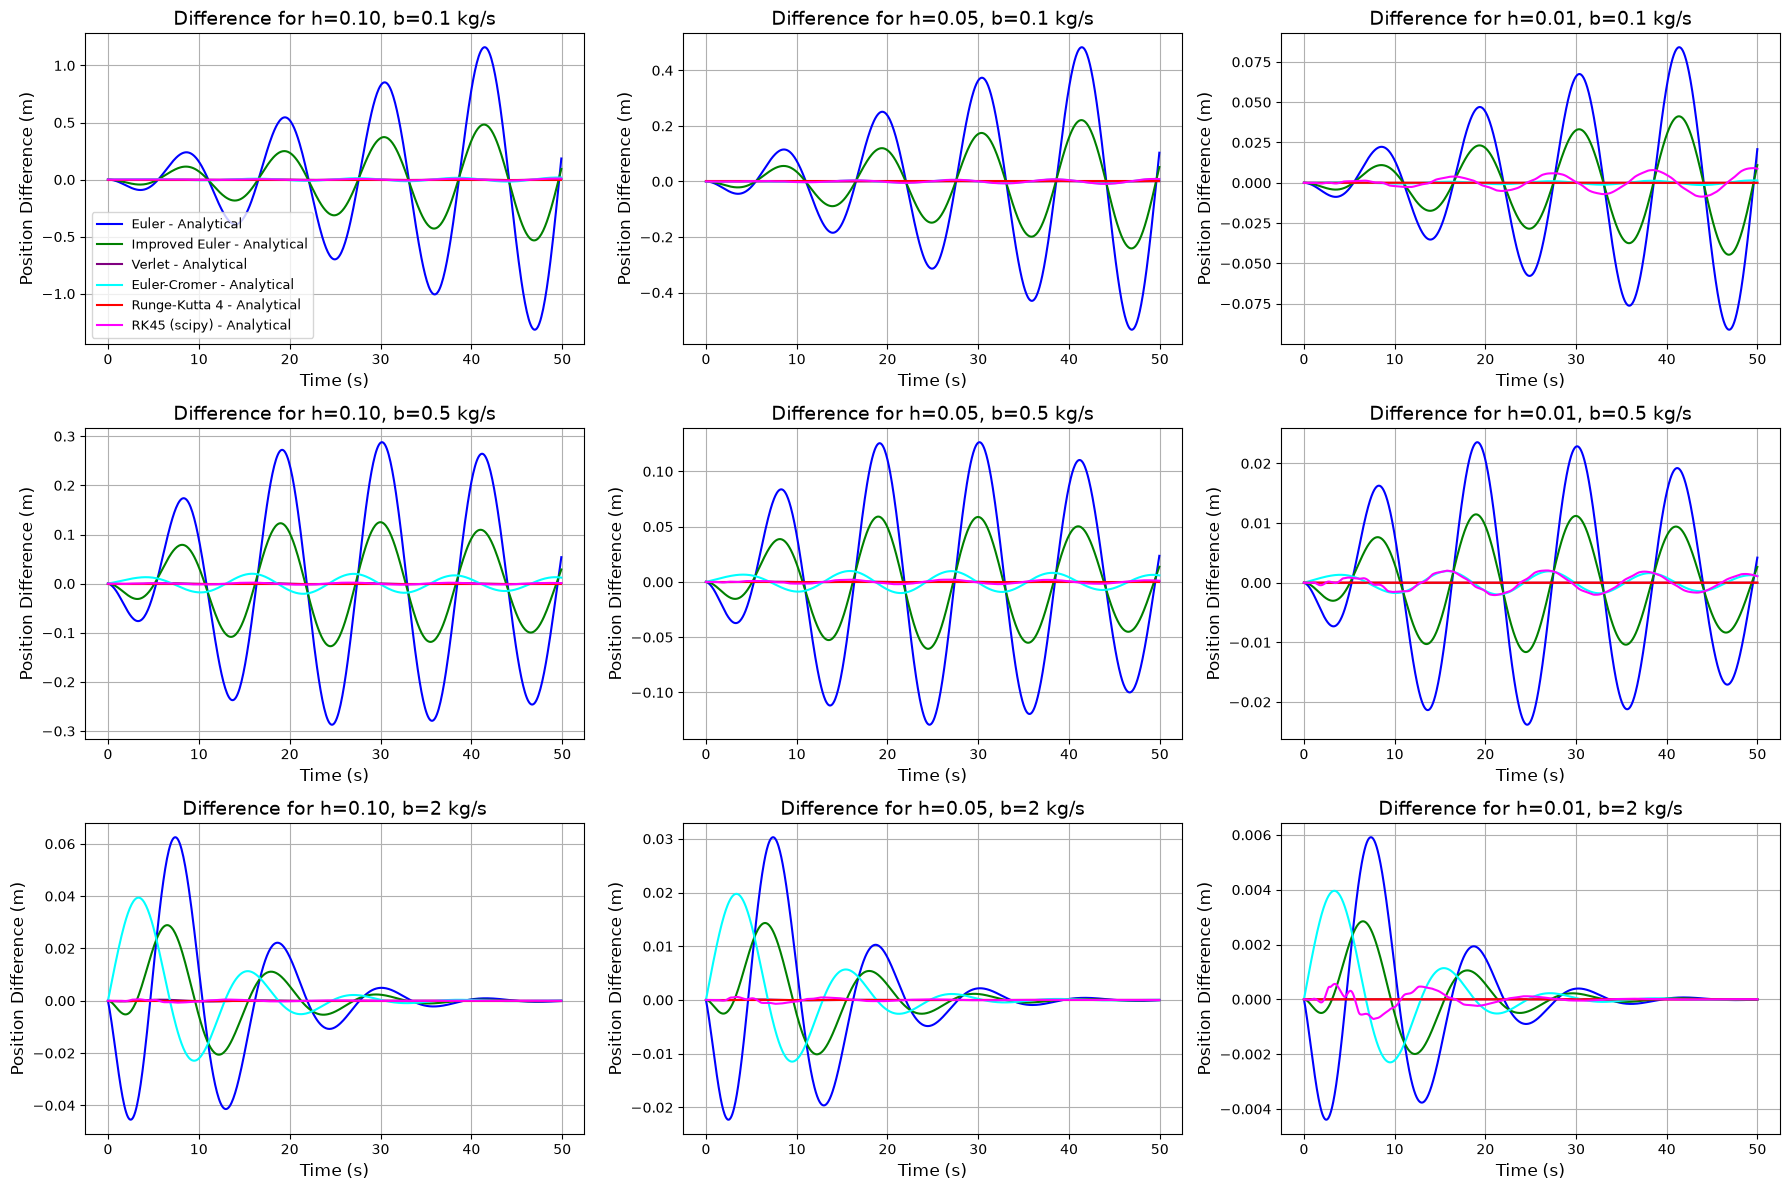

In [6]:
def plot_differences_combined(b_values, h_values, T):
    """
    Plotting the difference between the numerical method
    and the analytical solution. It visually shows how much
    each method differs from the expected values.
    """
    plt.figure(figsize=(18, 12))  # Adjust figure size to accommodate all subplots

    plot_number = 1
    # Iteration through all damping coeffcient then through all time steps
    for b_val in b_values:
        for hstep in h_values:
            t_range, x_analytic, positions = run_simulation(hstep, b_val, T)

            plt.subplot(len(b_values), len(h_values), plot_number)
            for name, x in positions.items():
                plt.plot(t_range, x - x_analytic, label=f'{name} - Analytical', color=COLORS[name])

            # Title and labels
            plt.title(f'Difference for h={hstep:.2f}, b={b_val:.3g} kg/s', fontsize=14)
            plt.xlabel('Time (s)', fontsize=12)
            plt.ylabel('Position Difference (m)', fontsize=12)
            if plot_number == 1:  # Add legend to the first subplot for clarity
                plt.legend(fontsize=9)
            plt.grid(True)

            plot_number += 1

    plt.tight_layout()
    plt.show()

# Call function to show all graphs
plot_differences_combined(b, h, T[0])

### Observation Notes 2

Runge-Kutta 4 and Verlet's methods have the smallest differences in every panel; on these linear axes their curves cannot be distinguished from zero. Euler-Cromer and RK45 have small but visible errors (for RK45 the error does not shrink with $h$, because its accuracy is set by its tolerance). The Euler and Improved Euler methods show differences that grow over time, through an amplitude that increases relative to the true one ($E \propto A^2$), so they gain energy compared with the physical system. This effect becomes smaller with smaller step sizes and larger damping.

### Calculations of damping coefficient 

This part of the code calculates critical values of damping coefficients in order to investigate behavior of the numerical methods under these special circumstances.

Critical damping 

$b_{cr} = 2\sqrt{km}$

Half-Critical damping

$b_{cr} = \sqrt{km}$

Double critical damping

$b_{cr} = 4\sqrt{km}$

In [7]:
def calculate_damping_constants(k, m):
    """
    This function calculates damping coefficients in critical scenarios: 
    half critical, critical, and double critical damping.
    """
    b_crit = 2 * math.sqrt(k * m)
    b_double = 4 * math.sqrt(k * m)
    b_half = math.sqrt(k * m)
    return b_crit, b_double, b_half

# Save all damping values as a array
b_crit, b_double, b_half = calculate_damping_constants(k, m)
b_values_critical = [b_half, b_crit, b_double]

# Print statements with damping numerical values calculated for all situations
print(f"Critical Damping Constant: {b_crit:.2f} kg/s")
print(f"Double the Critical Damping: {b_double:.2f} kg/s")
print(f"Half of the Critical Damping: {b_half:.2f} kg/s")

Critical Damping Constant: 6.36 kg/s
Double the Critical Damping: 12.71 kg/s
Half of the Critical Damping: 3.18 kg/s


### Total Energy comparison for lightly damped system
In this part of the code we investigated what happens to the total energy over time and how does it compare to the analytical solution for three values of the damping coefficient: $0.1$, $0.5$ and $2.0$ kg/s. Each damping has one colour: solid lines are the method, dashed lines the analytical energy.

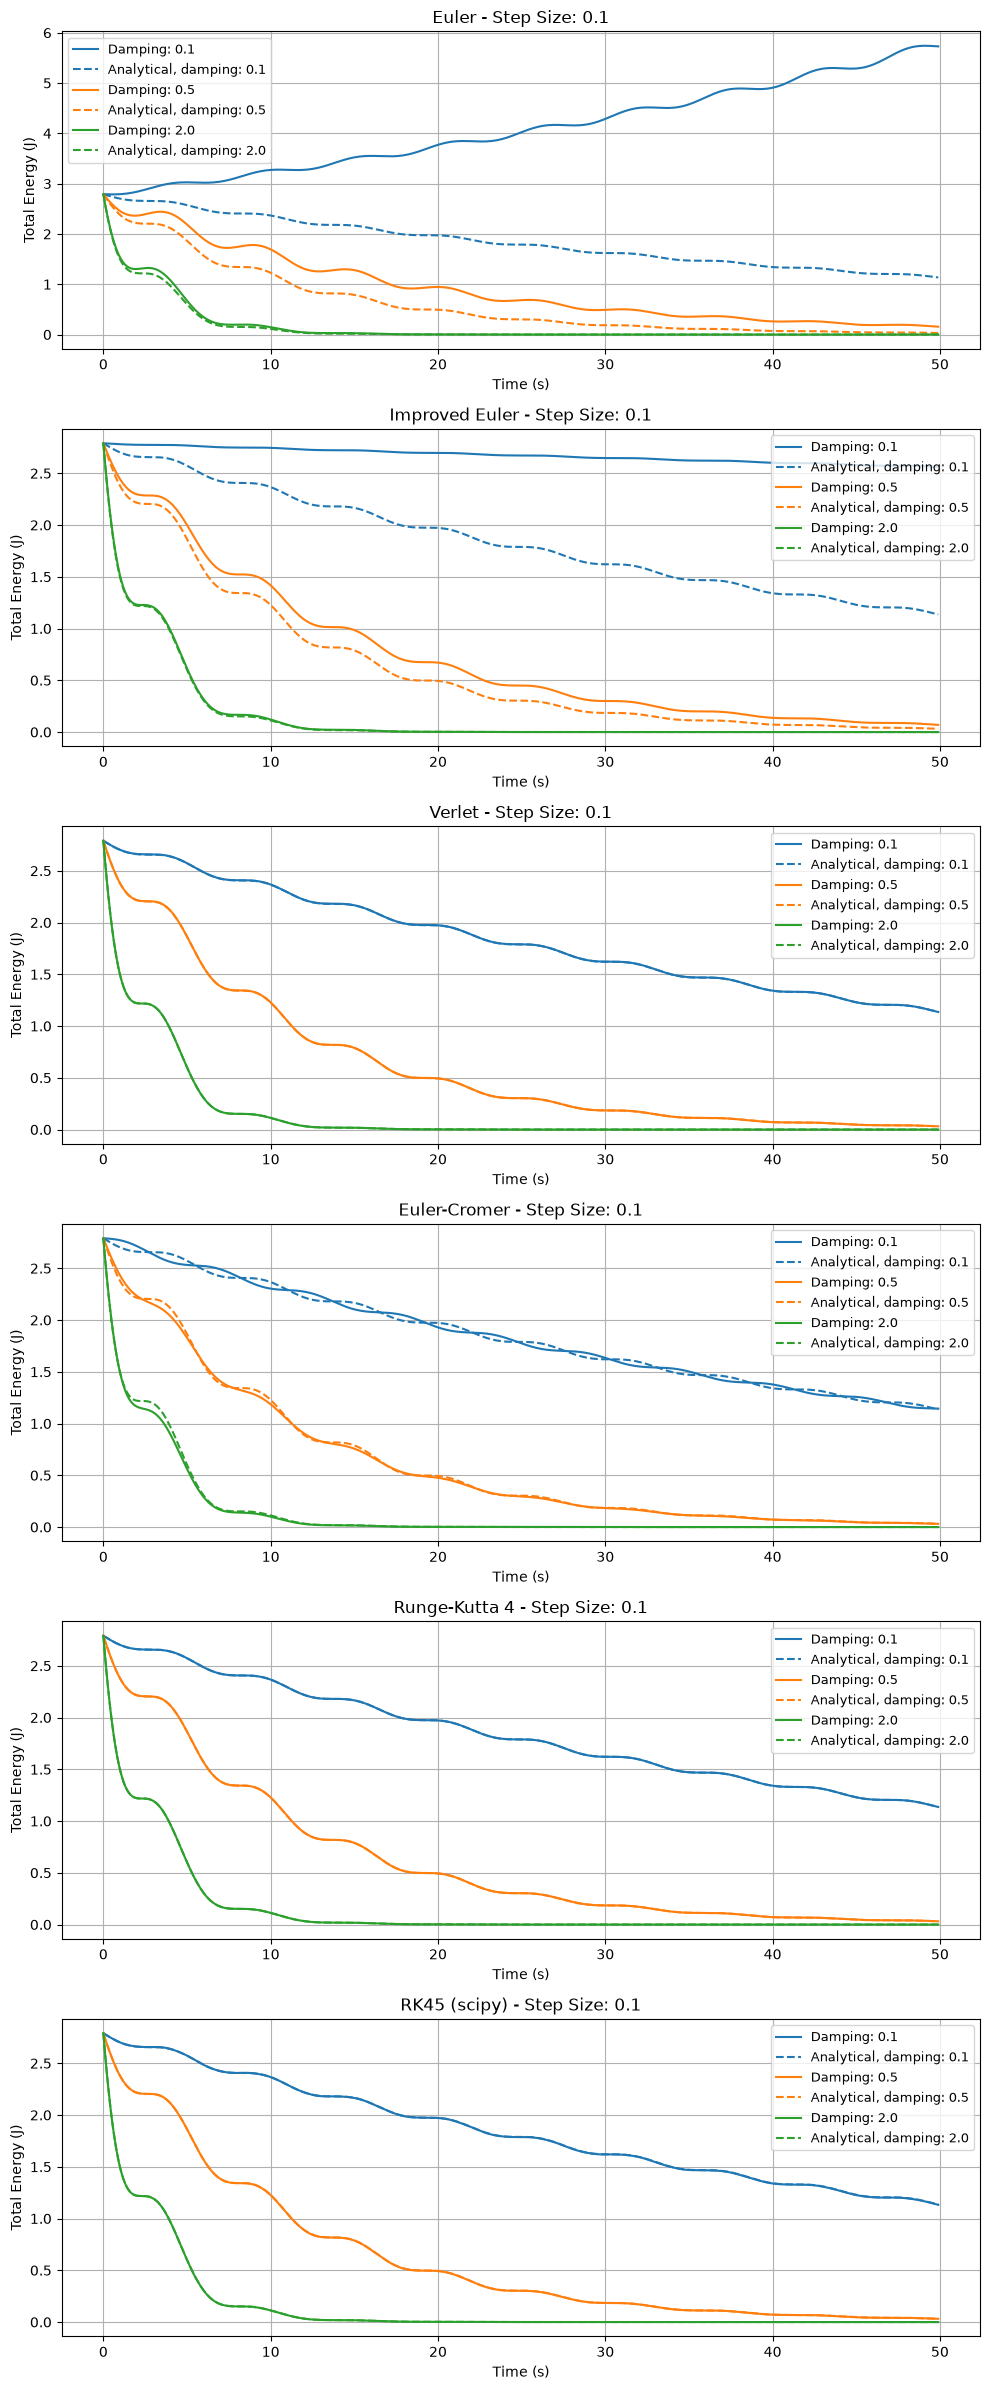

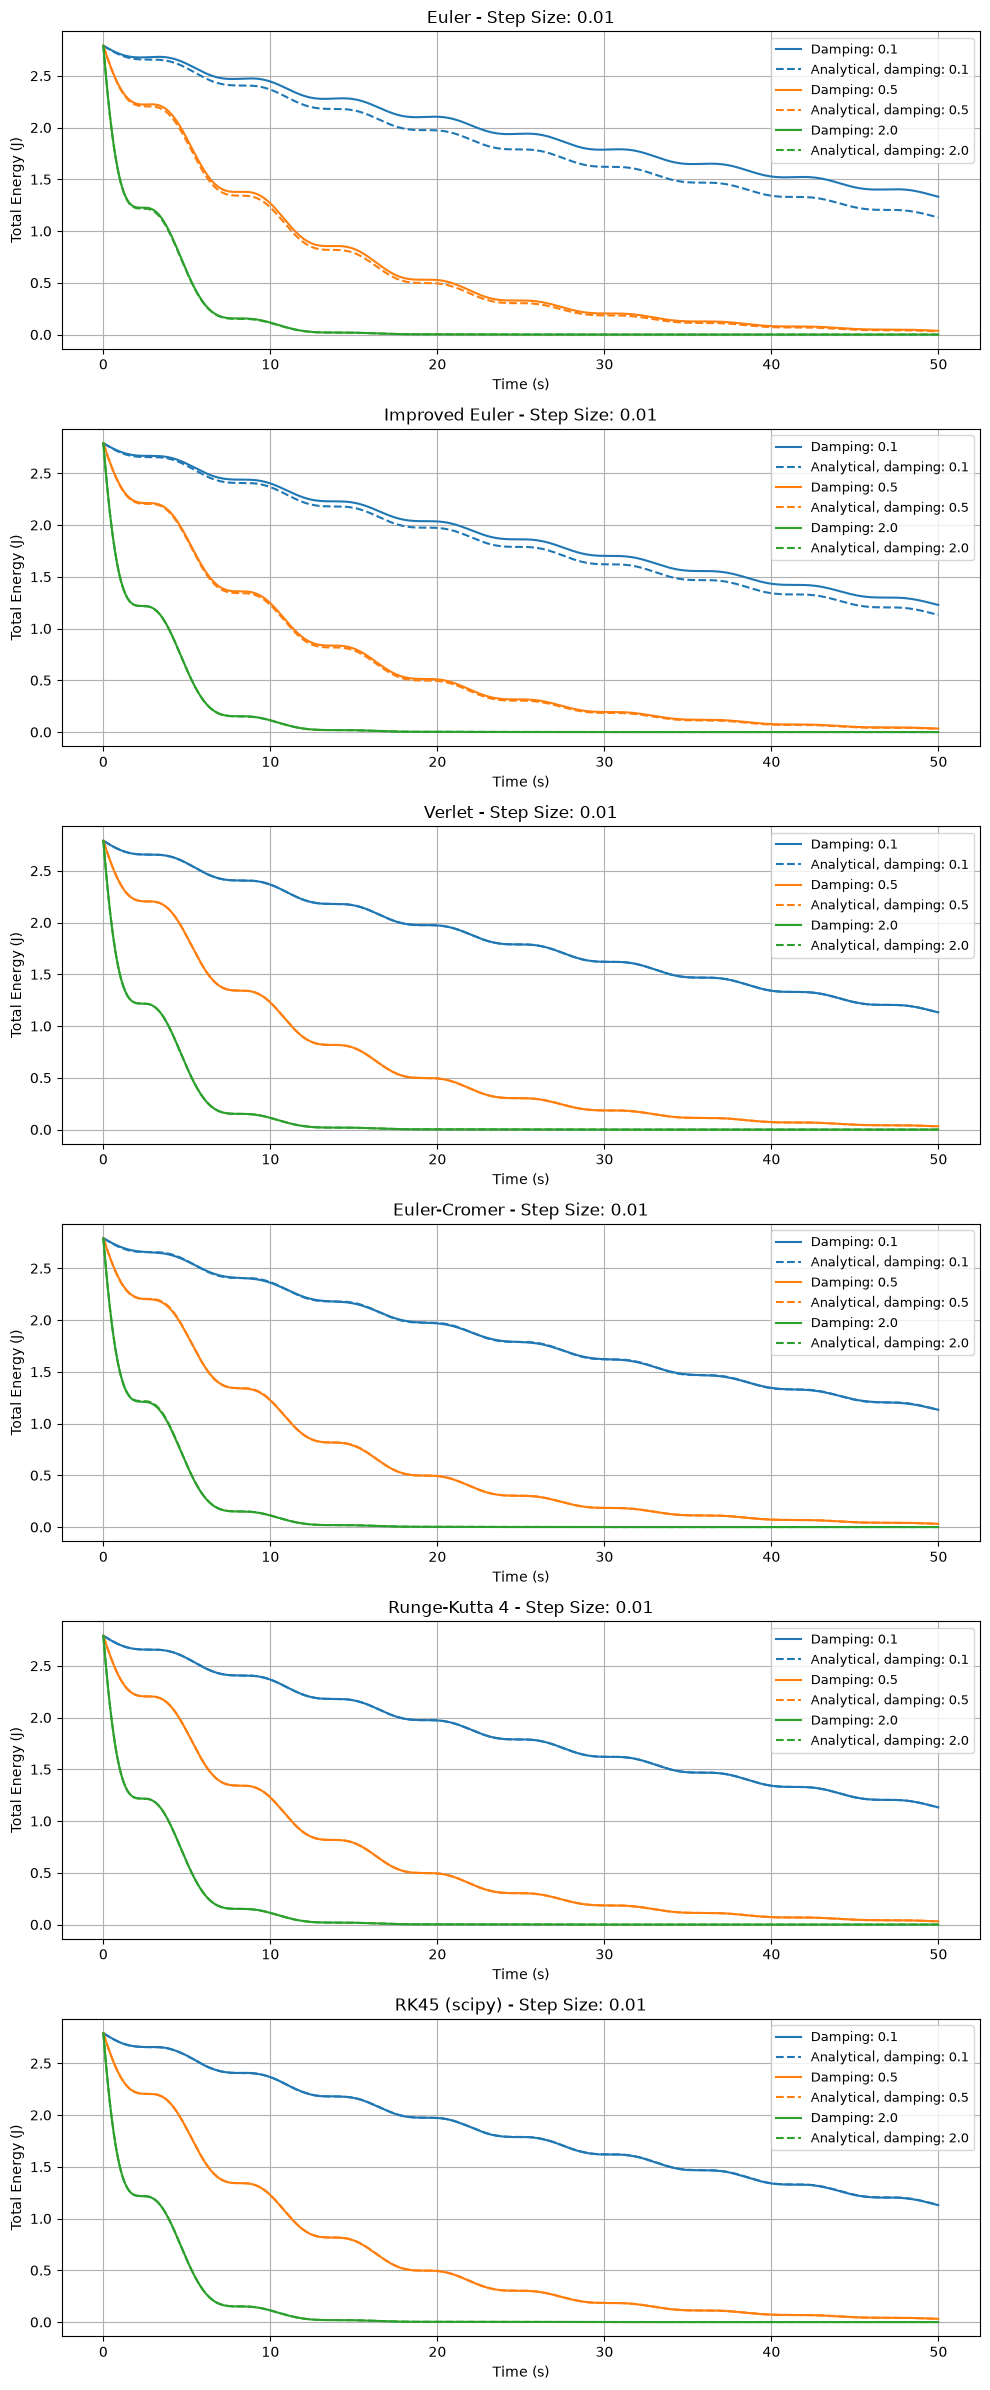

In [8]:
def total_energy_analytical(x0, v0, time, b):
    """
    This function defines analytical expression for the total energy of an underdamped system.
    """
    omega_0 = np.sqrt(k / m)  # Natural frequency
    gamma = b / (2 * m)        # Decay rate
    omega_d = np.sqrt(omega_0**2 - gamma**2)  # Damped angular frequency

    # Coefficients A and B
    A = x0
    B = (v0 + gamma * x0) / omega_d

    # Calculate position and velocity as functions of time
    x = A * np.exp(-gamma * time) * np.cos(omega_d * time) + B * np.exp(-gamma * time) * np.sin(omega_d * time)
    v = -gamma * A * np.exp(-gamma * time) * np.cos(omega_d * time) \
        - gamma * B * np.exp(-gamma * time) * np.sin(omega_d * time) \
        - A * omega_d * np.exp(-gamma * time) * np.sin(omega_d * time) \
        + B * omega_d * np.exp(-gamma * time) * np.cos(omega_d * time)

    # Calculate potential and kinetic energies
    U = 0.5 * k * x**2
    K = 0.5 * m * v**2

    # Total energy
    E = U + K
    return E

def plot_energy_vs_time_per_method(x0, v0, T, hstep, damping_values):
    """
    This function is plotting the energy versus time for every method.
    Each damping coefficient has one colour: solid for the method, dashed for the analytical energy.
    """
    nsteps, t_range = time_grid(T, hstep)
    plt.figure(figsize=(10, 4 * len(METHODS)))

    # Iteration through the methods, creating subplots and labelling
    for i, (method_name, method) in enumerate(METHODS.items()):
        plt.subplot(len(METHODS), 1, i + 1)
        plt.title(f'{method_name} - Step Size: {hstep}')
        plt.xlabel('Time (s)')
        plt.ylabel('Total Energy (J)')

        # Iteration through the dampings
        for j, damp_coeff in enumerate(damping_values):
            color = f'C{j}'
            _, _, energy = method(x0, v0, nsteps, hstep, damp_coeff)
            plt.plot(t_range, energy, color=color, label=f'Damping: {damp_coeff}')

            # Analytical energy (the expression above is for underdamped systems)
            if damp_coeff < b_crit:
                plt.plot(t_range, total_energy_analytical(x0, v0, t_range, damp_coeff), color=color,
                         linestyle='--', label=f'Analytical, damping: {damp_coeff}')

        # Legend and grid
        plt.legend(fontsize=9)
        plt.grid(True)

    plt.tight_layout()
    plt.show()

# Plot
plot_energy_vs_time_per_method(x0, v0, T[0], h[0], b)
plot_energy_vs_time_per_method(x0, v0, T[0], h[2], b)

### Observation notes 3

With a step size of $0.1$ s, Euler's method gains energy for $b=0.1$ kg/s (the energy rises above its initial value), and both Euler and Improved Euler lose energy more slowly than the analytical solution for all three damping coefficients. Euler-Cromer's energy oscillates about the analytical curve, which is the typical behaviour of a symplectic method. Verlet's and both Runge-Kutta methods lie on top of the analytical energy. With a step size of $0.01$ s all methods come much closer to the analytical energy, but Euler and Improved Euler still deviate the most.

(Before the correction, the analytical energy curves themselves were wrong, which showed up as out-of-phase differences between the analytical energy and all methods.)

### Further investigation using critical damping coefficients on the best methods

The process of plotting position against the time has been repeated for the best methods, Verlet's, Euler-Cromer's and both Runge-Kutta methods, with damping coefficients around the critical values: $\frac{b_{cr}}{2}, b_{cr}, 2b_{cr}$. It allows us to analyse behavior of the algorithms in critical conditions.

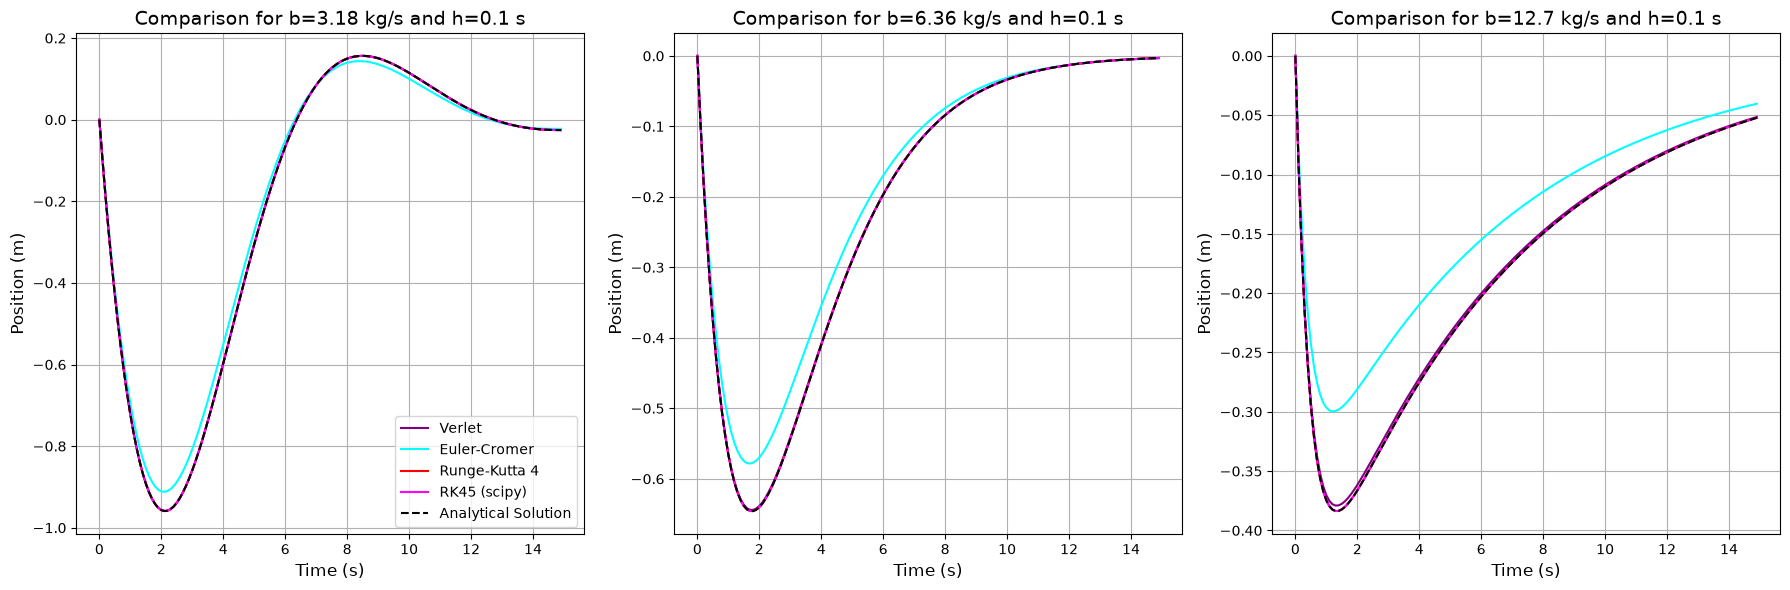

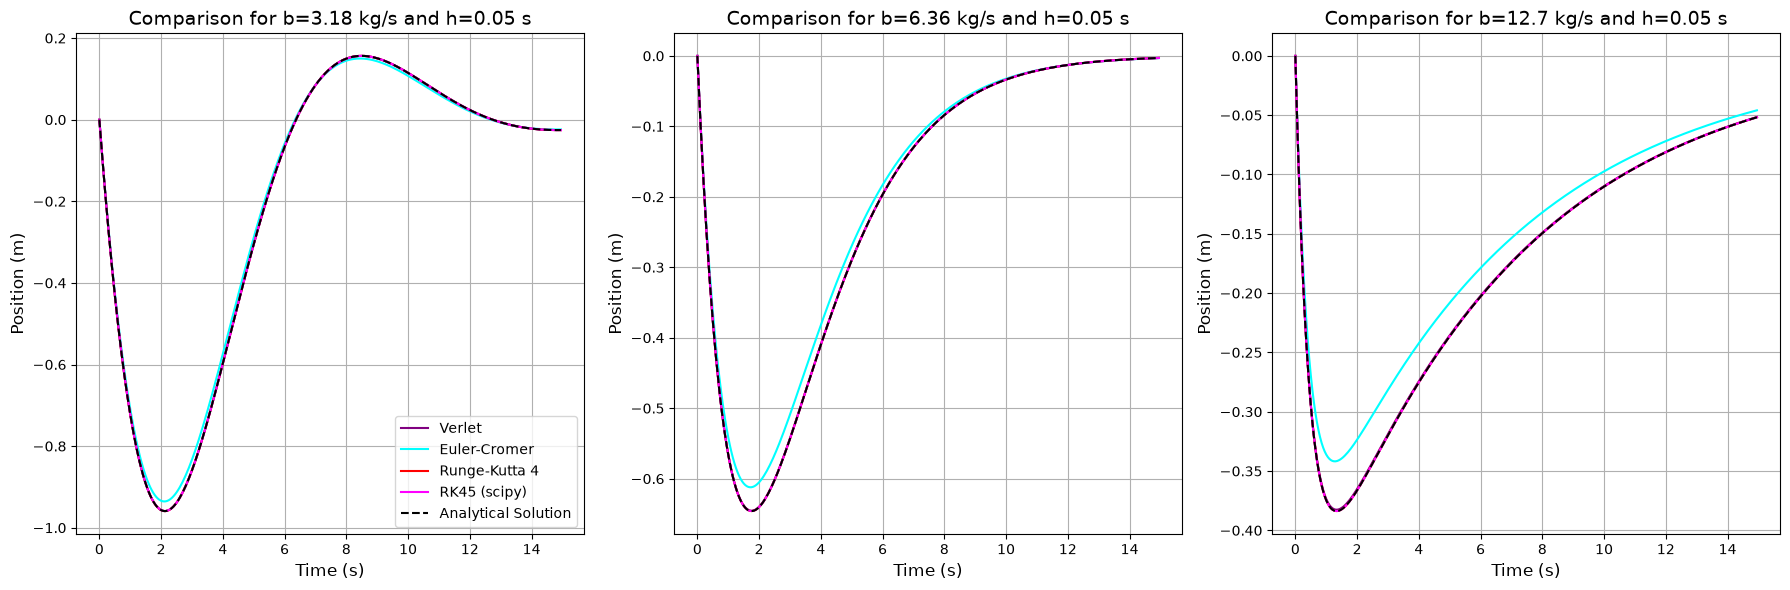

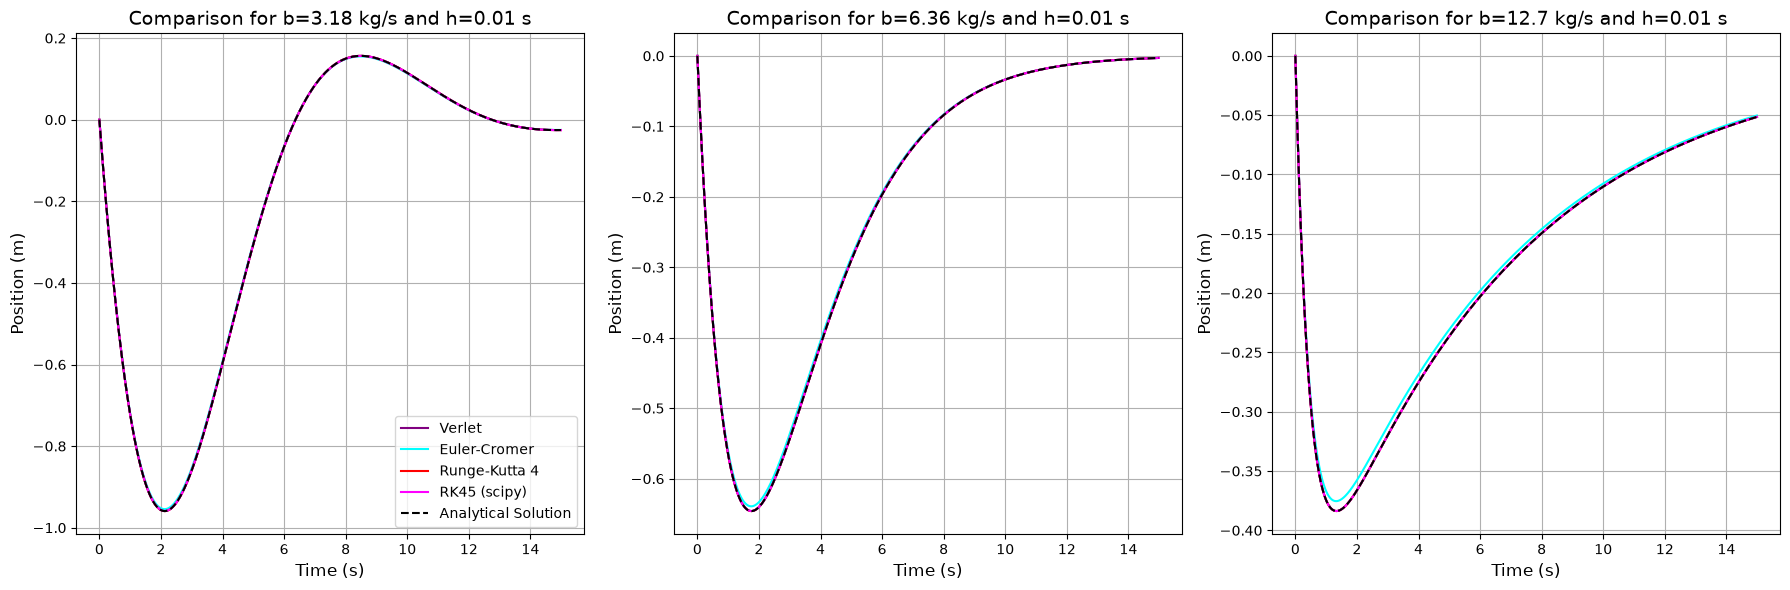

In [9]:
# Methods investigated further (RK45 is SciPy's adaptive version of Runge-Kutta)
BEST_METHODS = ['Verlet', 'Euler-Cromer', 'Runge-Kutta 4', 'RK45 (scipy)']

def plot_simulation_results_with_analytical(b_values, h_values, T):
    """
    This function is plotting the best methods in critical conditions
    showing analytical curve as a reference.
    """
    # Iteration through all time steps
    for hstep in h_values:
        # Adjusting figure size
        plt.figure(figsize=(18, 6))

        # Iteration through all damping coefficients
        for index, b_val in enumerate(b_values, start=1):
            plt.subplot(1, len(b_values), index)
            # The analytical solution is chosen for the damping regime inside run_simulation
            t_range, x_analytic, positions = run_simulation(hstep, b_val, T, BEST_METHODS)
            plot_positions(t_range, x_analytic, positions,
                           f'Comparison for b={b_val:.3g} kg/s and h={hstep:.3g} s', index == 1)

        plt.tight_layout()
        plt.show()

# Call for plotting
plot_simulation_results_with_analytical(b_values_critical, h, 15)

### Observations Notes 4

Note, that we shorten total time down to $15$ seconds to present the differences more accurately.

Euler-Cromer's method visibly deviates from the analytical solution for the largest step size, and the deviation grows with the damping (its error is first order in $h$, and the damping term is treated explicitly). Verlet's method and both Runge-Kutta methods match the analytical solutions closely for every damping and step size; differences between them are only seen in the error values in the next sections.

### Error calculated using three different methods

We used following constants:
Damping coefficients: 0.1, 0.5, 2.0 kg/s and half critical damping 3.18 kg/s
Time step size: 0.1 s
Total time: 300 s

We will look at the numerical values of errors determined in three different ways. This code will automatically determine best method assuming that smallest error implies the highest accuracy. The step size was chosen to be the largest among all investigated to see how these functions behave in this situation.

#### Methods used in these calculations:

##### Mean Absolute Error (MAE):

$$MAE = \frac{1}{n}\sum^n_{i=1}|y_{actual}-y_{predicted}|$$

##### Mean Squared Error (MSE):

$$MSE = \frac{1}{n}\sum^n_{i=1}(y_{actual}-y_{predicted})^2$$

##### Root Mean Squared Error (RMSE):

$$RMSE = \sqrt{\frac{1}{n}\sum^n_{i=1}(y_{actual}-y_{predicted})^2}$$

where $n$ is the total number of data points, $y_{actual} - y_{predicted}$ is the difference between the positions in numerical method and analytical solution. MAE and RMSE are in metres, MSE in m².

In [10]:
def calculate_errors(y_actual, y_predicted):
    """
    This function calculates the errors using three different methods:
    Mean Absolute Error, Mean Squared Error, and Root Mean Squared Error.
    """
    differences = y_actual - y_predicted
    mae = np.mean(np.abs(differences)) # Mean Absolute Error (m)
    mse = np.mean(np.square(differences)) # Mean Squared Error (m^2)
    rmse = np.sqrt(mse) # Root Mean Squared Error (m)
    return mae, mse, rmse

def run_simulation_and_calculate_errors(b, hstep, T, methods=None):
    """
    Computing errors for the chosen methods and determining the most accurate one.
    """
    # Run simulation on the common time grid
    t_range, x_analytic, positions = run_simulation(hstep, b, T, methods)

    # Calculate errors for every method
    errors = [(name, *calculate_errors(x_analytic, x)) for name, x in positions.items()]

    # Sort methods by RMSE, MSE, and MAE respectively
    errors_sorted_by_rmse = sorted(errors, key=lambda x: x[3])
    errors_sorted_by_mse = sorted(errors, key=lambda x: x[2])
    errors_sorted_by_mae = sorted(errors, key=lambda x: x[1])

    # Printing errors
    print(f"Simulation Errors for h={hstep:.3g} s, b={b:.3g} kg/s:")
    print("---------------------------------------------------")
    for name, mae, mse, rmse in errors_sorted_by_rmse:
        print(f"{name}:")
        print(f"  - Mean Absolute Error (MAE): {mae:.3g} m")
        print(f"  - Mean Squared Error (MSE): {mse:.3g} m^2")
        print(f"  - Root Mean Squared Error (RMSE): {rmse:.3g} m")
    print("---------------------------------------------------")

    # Print the best method based on RMSE, MSE, and MAE
    print(f"Best Method Based on RMSE: {errors_sorted_by_rmse[0][0]} (RMSE={errors_sorted_by_rmse[0][3]:.3g} m)")
    print(f"Best Method Based on MSE: {errors_sorted_by_mse[0][0]} (MSE={errors_sorted_by_mse[0][2]:.3g} m^2)")
    print(f"Best Method Based on MAE: {errors_sorted_by_mae[0][0]} (MAE={errors_sorted_by_mae[0][1]:.3g} m)")
    print("---------------------------------------------------\n")

# Call the function
for b_val in [b[0], b[1], b[2], b_values_critical[0]]:
    run_simulation_and_calculate_errors(b_val, h[0], T[2])

Simulation Errors for h=0.1 s, b=0.1 kg/s:
---------------------------------------------------
Runge-Kutta 4:
  - Mean Absolute Error (MAE): 1.74e-06 m
  - Mean Squared Error (MSE): 4.03e-12 m^2
  - Root Mean Squared Error (RMSE): 2.01e-06 m
Verlet:
  - Mean Absolute Error (MAE): 0.0027 m
  - Mean Squared Error (MSE): 9.65e-06 m^2
  - Root Mean Squared Error (RMSE): 0.00311 m
RK45 (scipy):
  - Mean Absolute Error (MAE): 0.00584 m
  - Mean Squared Error (MSE): 4.57e-05 m^2
  - Root Mean Squared Error (RMSE): 0.00676 m
Euler-Cromer:
  - Mean Absolute Error (MAE): 0.0116 m
  - Mean Squared Error (MSE): 0.000179 m^2
  - Root Mean Squared Error (RMSE): 0.0134 m
Improved Euler:
  - Mean Absolute Error (MAE): 0.598 m
  - Mean Squared Error (MSE): 0.498 m^2
  - Root Mean Squared Error (RMSE): 0.706 m
Euler:
  - Mean Absolute Error (MAE): 3.61 m
  - Mean Squared Error (MSE): 24.7 m^2
  - Root Mean Squared Error (RMSE): 4.97 m
---------------------------------------------------
Best Method Based

### Observation notes 5

Runge-Kutta 4 has by far the smallest error in all four cases, with $MSE = 4.0\times10^{-12}$, $3.6\times10^{-14}$, $6.5\times10^{-16}$ and $1.8\times10^{-16}$ m² for $b = 0.1$, $0.5$, $2.0$ and $3.18$ kg/s. Verlet's method is second best for the three lower dampings and RK45 for half critical damping; the RK45 error ($MSE = 4.6\times10^{-5}$ m² at $b=0.1$ kg/s) is limited by its default tolerance. Euler-Cromer follows, and Euler and Improved Euler are the least accurate for light damping ($MSE = 24.7$ and $0.50$ m² at $b=0.1$ kg/s). As the damping increases, the errors of the first-order methods become similar: at $b=2.0$ kg/s Improved Euler, and at $3.18$ kg/s both Improved Euler and Euler, are slightly more accurate than Euler-Cromer.

(Before the correction, Euler-Cromer appeared best for $b=0.1$ kg/s. That was caused by the Runge-Kutta solution being compared with the analytical solution at slightly different times.)

### Errors calculated using three different methods for critically damped and heavy damped system

This part investigates errors in critical conditions (critical and double critical damping, total time 50 s) for the best methods: Verlet's, Euler-Cromer's and both Runge-Kutta methods, for each of the three step sizes.

In [11]:
# Critical and double critical damping
b_values = [b_values_critical[1], b_values_critical[2]]

# Iteration through all damping values and time steps for the best methods
for b_val in b_values:
    for hstep in h:
        run_simulation_and_calculate_errors(b_val, hstep, T[0], BEST_METHODS)

Simulation Errors for h=0.1 s, b=6.36 kg/s:
---------------------------------------------------
Runge-Kutta 4:
  - Mean Absolute Error (MAE): 1.78e-08 m
  - Mean Squared Error (MSE): 3.05e-15 m^2
  - Root Mean Squared Error (RMSE): 5.52e-08 m
RK45 (scipy):
  - Mean Absolute Error (MAE): 6.58e-06 m
  - Mean Squared Error (MSE): 3.06e-10 m^2
  - Root Mean Squared Error (RMSE): 1.75e-05 m
Verlet:
  - Mean Absolute Error (MAE): 0.000184 m
  - Mean Squared Error (MSE): 2.25e-07 m^2
  - Root Mean Squared Error (RMSE): 0.000474 m
Euler-Cromer:
  - Mean Absolute Error (MAE): 0.00709 m
  - Mean Squared Error (MSE): 0.000359 m^2
  - Root Mean Squared Error (RMSE): 0.019 m
---------------------------------------------------
Best Method Based on RMSE: Runge-Kutta 4 (RMSE=5.52e-08 m)
Best Method Based on MSE: Runge-Kutta 4 (MSE=3.05e-15 m^2)
Best Method Based on MAE: Runge-Kutta 4 (MAE=1.78e-08 m)
---------------------------------------------------

Simulation Errors for h=0.05 s, b=6.36 kg/s:
----

Simulation Errors for h=0.1 s, b=12.7 kg/s:
---------------------------------------------------
Runge-Kutta 4:
  - Mean Absolute Error (MAE): 9.65e-08 m
  - Mean Squared Error (MSE): 2.49e-13 m^2
  - Root Mean Squared Error (RMSE): 4.99e-07 m
RK45 (scipy):
  - Mean Absolute Error (MAE): 1.99e-06 m
  - Mean Squared Error (MSE): 2.53e-11 m^2
  - Root Mean Squared Error (RMSE): 5.03e-06 m
Verlet:
  - Mean Absolute Error (MAE): 0.000783 m
  - Mean Squared Error (MSE): 2.15e-06 m^2
  - Root Mean Squared Error (RMSE): 0.00147 m
Euler-Cromer:
  - Mean Absolute Error (MAE): 0.014 m
  - Mean Squared Error (MSE): 0.000705 m^2
  - Root Mean Squared Error (RMSE): 0.0266 m
---------------------------------------------------
Best Method Based on RMSE: Runge-Kutta 4 (RMSE=4.99e-07 m)
Best Method Based on MSE: Runge-Kutta 4 (MSE=2.49e-13 m^2)
Best Method Based on MAE: Runge-Kutta 4 (MAE=9.65e-08 m)
---------------------------------------------------

Simulation Errors for h=0.05 s, b=12.7 kg/s:
------

### Observation notes 6

In the critical conditions (critical damping and double critical damping), Runge-Kutta 4 is the most accurate method for every step size, and its error falls by about $2^4 = 16$ when the step size is halved. RK45 comes second for $h = 0.1$ and $0.05$ s, but its error stays at about $6.6\times10^{-6}$ m (critical damping) for every step size, so at $h=0.01$ s Verlet's method overtakes it for critical damping. Euler-Cromer has the largest error throughout.

### Visual representation of errors

The errors can be plotted against the time step to observe how accuracy changes as the time step size varies. On log-log axes a method whose error is proportional to $h^p$ is a straight line of slope $p$, the order of the method; the fitted slope is shown in the legend (errors above 1 m, where a method has effectively failed, are left out of the fit).

##### First part:
Investigate low dampings $[0.1, 0.5, 2.0, 3.18]$ kg/s across the range of step size between $0.01 - 0.1$ seconds.

##### Second Part:
Investigate critical dampings $[6.36, 12.71]$ kg/s across the same range of time steps.

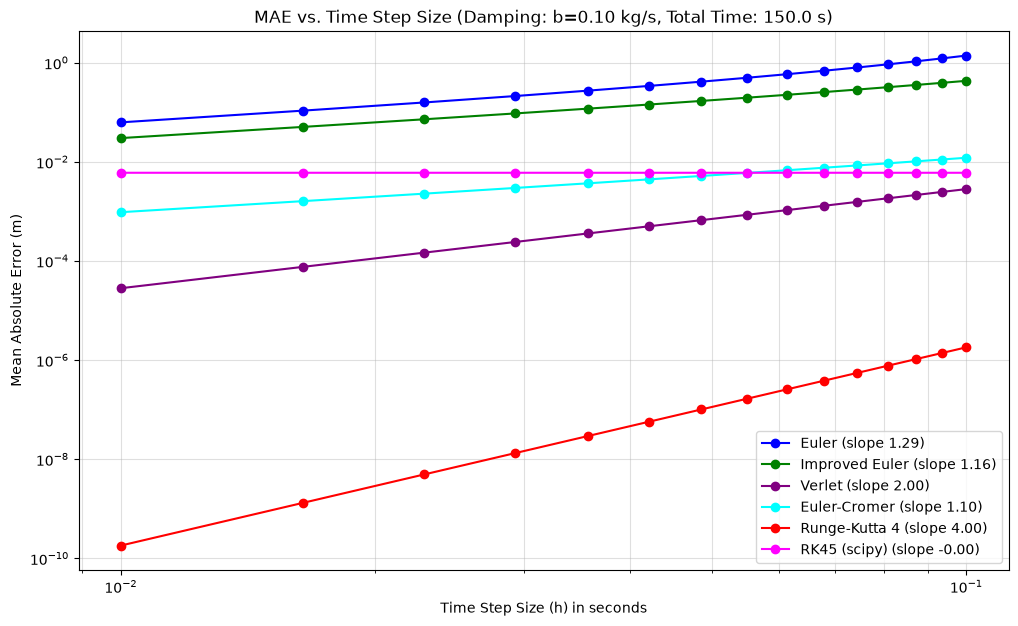

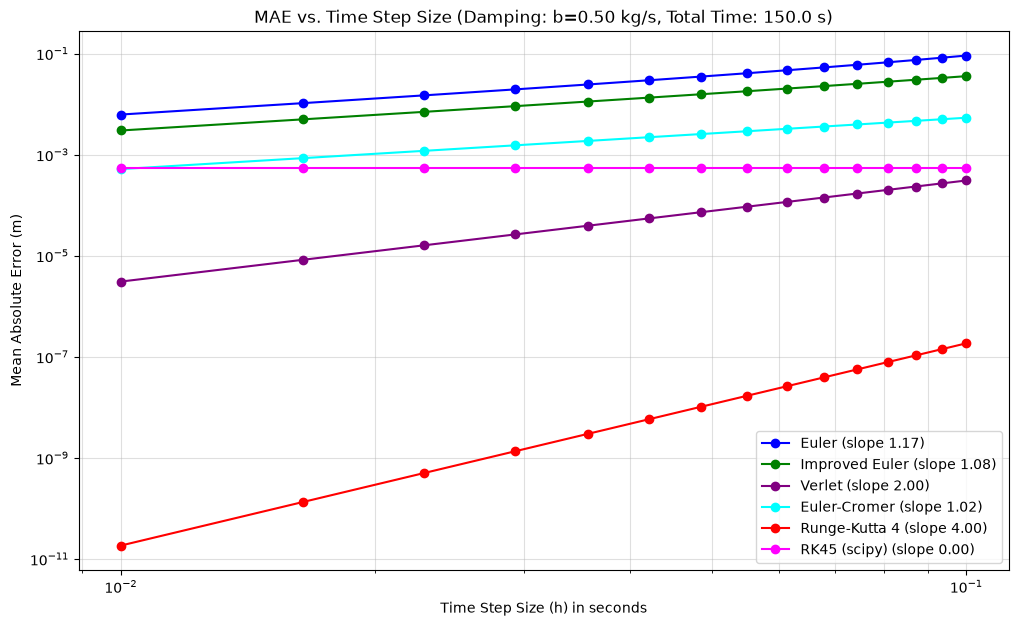

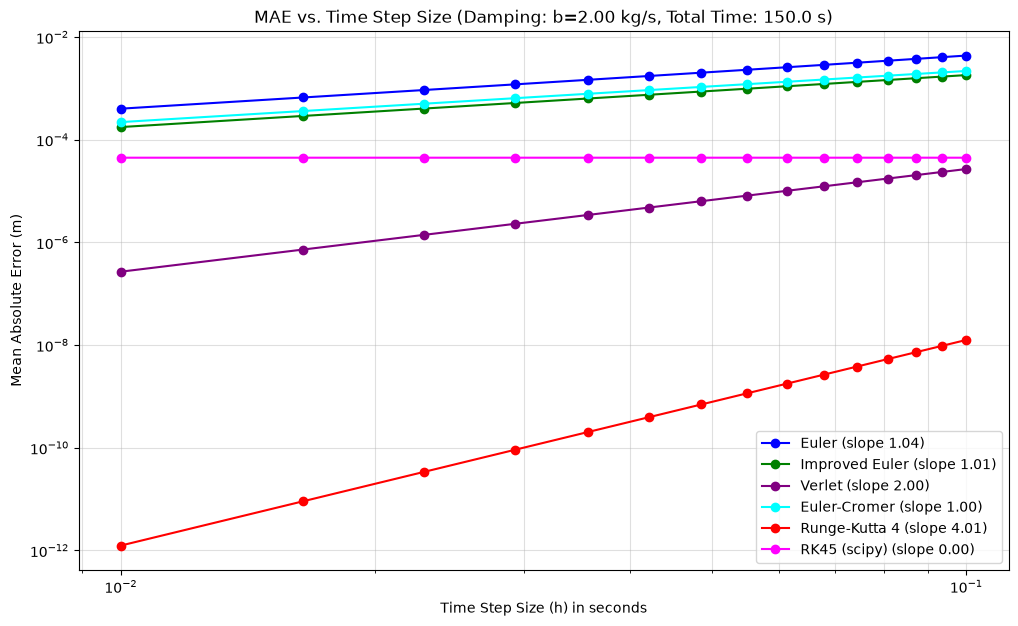

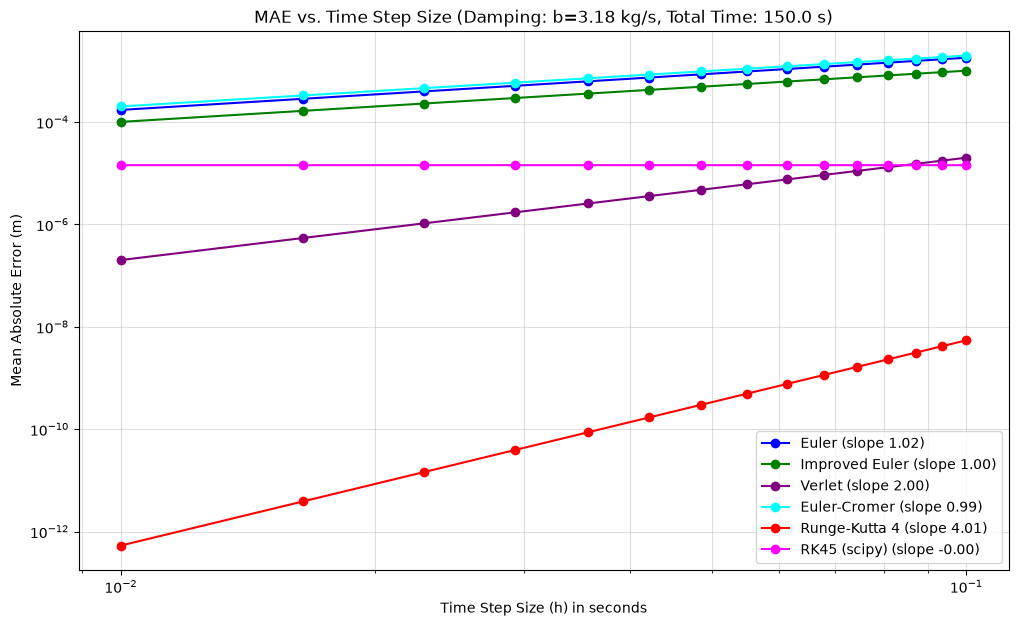

In [12]:
h_values = np.linspace(0.01, 0.1, 15)  # Range of h values

def calculate_mae_all_methods_over_h(h_values, b, T, methods=None):
    """
    It calculates Mean Absolute Error of the chosen methods for an array of time step sizes h.
    """
    mae_values = {name: [] for name in (methods or METHODS)}  # Dictionary to store MAE values for each method

    # Iteration through all time steps
    for hstep in h_values:
        t_range, x_analytic, positions = run_simulation(hstep, b, T, methods)
        for name, x in positions.items():
            mae_values[name].append(np.mean(np.abs(x - x_analytic)))

    return mae_values

def observed_order(h_values, errors):
    """
    Slope p of log(error) against log(h), i.e. error ~ h^p. Errors at the round-off level (< 1e-12 m)
    or of a method that has blown up (> 1 m) are left out.
    """
    errors = np.asarray(errors)
    usable = np.isfinite(errors) & (errors > 1e-12) & (errors < 1)
    if np.count_nonzero(usable) < 2:
        return np.nan
    return np.polyfit(np.log(h_values[usable]), np.log(errors[usable]), 1)[0]

def plot_mae_over_h(h_values, mae_values, title):
    """
    Plotting function for MAE vs h on log-log axes. A method with error ~ h^p is a straight
    line of slope p, shown in the legend.
    """
    plt.figure(figsize=(12, 7))
    for name, maes in mae_values.items():
        p = observed_order(h_values, maes)
        plt.loglog(h_values, maes, label=f'{name} (slope {p:.2f})', marker='o', linestyle='-', color=COLORS[name])

    # Title and labels
    plt.xlabel('Time Step Size (h) in seconds')
    plt.ylabel('Mean Absolute Error (m)')
    plt.title(title)
    plt.legend()
    plt.grid(True, which='both', alpha=0.4)
    plt.show()

def analyze_and_plot_mae_for_dampings(h_values, dampings, T, methods=None):
    """
    It runs the plotting function MAE against the step size for every damping coefficient.
    """
    for b_val in dampings:
        mae_values = calculate_mae_all_methods_over_h(h_values, b_val, T, methods)
        plot_mae_over_h(h_values, mae_values, f'MAE vs. Time Step Size (Damping: b={b_val:.2f} kg/s, Total Time: {T} s)')

b_array = [0.1, 0.5, 2.0, b_half]
# Analyze and plot MAE for specified dampings
analyze_and_plot_mae_for_dampings(h_values, b_array, T[1])

### Observation notes 7
The slopes confirm the expected orders of accuracy: about 1 for Euler, Improved Euler and Euler-Cromer, 2 for Verlet and 4 for Runge-Kutta 4. (For $b=0.1$ kg/s the Euler slope is slightly above 1 because its errors approach the size of the oscillation itself.) The RK45 error is a horizontal line: it is set by the solver's tolerance, not by $h$. Runge-Kutta 4 is the most accurate method for every damping and step size, by several orders of magnitude. At the smallest damping Euler-Cromer is clearly better than Euler and Improved Euler, while for larger damping the three first-order methods give similar errors.

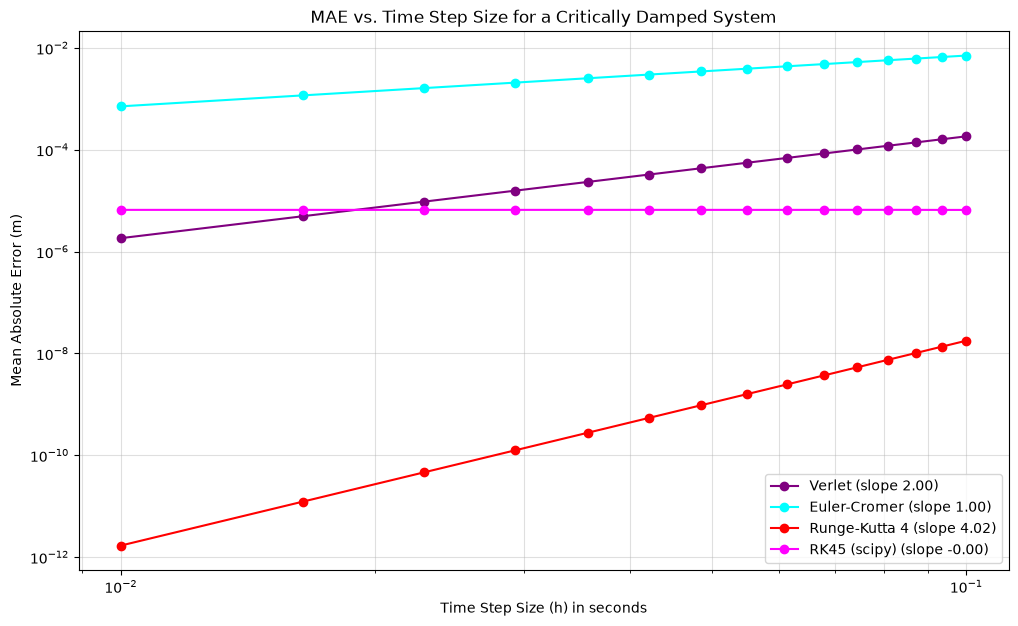

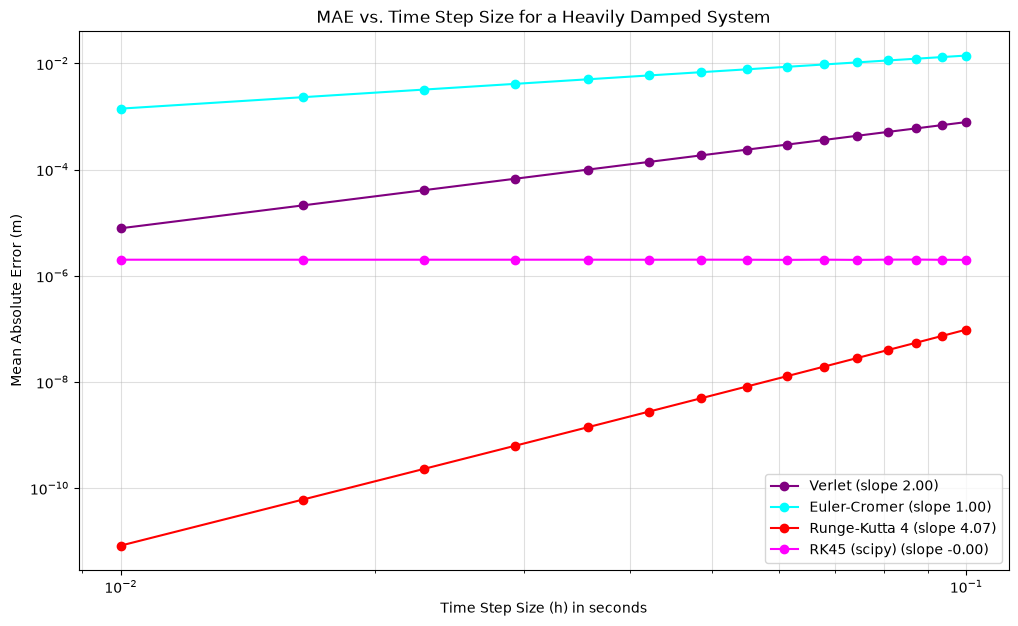

In [13]:
# Critical and heavy damping, for the best methods
dampings_info = [
    (b_crit, "MAE vs. Time Step Size for a Critically Damped System"),
    (b_double, "MAE vs. Time Step Size for a Heavily Damped System"),
]

for b_val, title in dampings_info:
    mae_values = calculate_mae_all_methods_over_h(h_values, b_val, T[0], BEST_METHODS)
    plot_mae_over_h(h_values, mae_values, title)

### Observation notes 8
In critical conditions Runge-Kutta 4 remains the best method, with slope 4. Verlet's method (slope 2) is more accurate than Euler-Cromer's (slope 1) by about two orders of magnitude, and becomes more accurate than RK45 at small step sizes for critical damping.

### External Force: Sudden and Sinusoidal
The investigation focuses on a damped mass-spring system subjected to two distinct types of external forces. The first is a transient, impulsive force with a specific duration, while the second is a continuous, sinusoidal force. Computational simulations are conducted utilizing the Runge-Kutta method (SciPy RK45 with tight tolerances), and compared with the exact analytical solutions of the driven system as well as with the motion without the force. The scenarios explore varying magnitudes of the applied force to observe and analyze the system's dynamic behavior.

Particularly in the case of the sudden force, the simulation captures the velocity of the system at the precise moment of force application. This enables an in-depth examination of the interplay between the direction of the system's velocity and the direction of the applied force. The analysis seeks to understand how opposing and aiding directions between force and motion influence the energy transfer within the system, affecting its subsequent oscillatory motion.

#### Sudden Force:
$$F(t) = F_{ext}$$

Equation of motion becomes

$$m\ddot{x}+b\dot{x}+kx=F_{ext}$$

This force is constant and last the duration specified in the code. In here we choose 3 seconds duration for clearer representation of the sudden effect of external force on the system. The magnitudes of force that are under this investigation are $0.5$ and $\pm 2.5$ N.

#### Sinusoidal Force:
$$F(t) = F_{ext}\cos{(\omega t+\phi)}$$

Equation of motion becomes

$$m\ddot{x}+b\dot{x}+kx=F_{ext}\cos{(\omega t+\phi)}$$

This is dynamical force that acts on the system throughout the simulation. Firstly, we set phase to be zero, and angular frequency to be low $0.9$ rad/s. The magnitude of the force remains the same as in sudden force case.

##### Parameters used in this analysis:
$b = 0.5$ kg/s

$h = 0.01$ s

$F_{ext} = 0.5$ and $\pm 2.5$ N

Total time $= 150$ s

$\phi = 0$

$\omega_{ext} = 0.9$ rad/s

Time applied of sudden force $= 20$ s and $38$ s

Duration of sudden force $= 3$ s for all

### Parameters and driving force Runge-Kutta function

In [14]:
# Parameters for the force functions
F_ext = [0.5, 2.5, -2.5]  # Magnitude of the external force (N)
t_apply = 20  # Time to apply the sudden force (s)
t_apply2 = 38  # Time to apply the sudden force (s)
omega_ext = 0.9  # Frequency of the external force (rad/s)
duration = 3 # Sudden force is applied for the certain duration (in seconds)
phi = 0 # Phase

# Number of steps and time range
nsteps, t_range = time_grid(T[1], h[2])

# Runge-Kutta Method with Driving Force
def RungeKuttaDrivingForce(x0, v0, nsteps, hstep, force_func, force_params, b, max_step=np.inf):
    """
    This is Runge-Kutta (SciPy RK45) function with driving force. Tight tolerances are used so the
    numerical error is negligible on the plots, and max_step stops the solver from stepping over a short pulse.
    """
    t_eval = hstep * np.arange(nsteps)
    t_span = [0, t_eval[-1]]

    def mass_spring_damper_system_with_drive(t, y):
        x, v = y
        dxdt = v
        # The driving force is evaluated at the current time
        driving_force = force_func(t, **force_params)
        dvdt = (driving_force - b * v - k * x) / m
        return [dxdt, dvdt]

    y0 = [x0, v0]
    sol = solve_ivp(mass_spring_damper_system_with_drive, t_span, y0, method='RK45', t_eval=t_eval,
                    rtol=1e-9, atol=1e-12, max_step=max_step)

    return sol.t, sol.y[0], sol.y[1]

### Analytical solutions with a driving force

The driven system also has exact solutions, so the Runge-Kutta results can be checked directly instead of being compared with the unforced motion.

**Sudden force.** While the constant force $F_{ext}$ acts, $x - F_{ext}/k$ obeys the free equation of motion. The solution is therefore built from three free solutions: before the force, while it acts (oscillating about $F_{ext}/k$), and after it stops, each starting from the position and velocity where the previous one ended.

**Sinusoidal force.** The solution is the steady-state response plus a free (transient) solution that matches the initial conditions,

$$x(t) = A\cos(\omega t + \phi - \delta) + x_{free}(t), \qquad A = \frac{F_{ext}}{\sqrt{(k-m\omega^2)^2 + (b\omega)^2}}, \qquad \tan\delta = \frac{b\omega}{k - m\omega^2}.$$

The free solution for any damping is written as $x(t) = e^{-\gamma t}\left[x_0 C(t) + (v_0+\gamma x_0) S(t)\right]$ with $\gamma = b/2m$, where $C=\cos\omega_d t$, $S=\sin(\omega_d t)/\omega_d$ for underdamping, $C=1$, $S=t$ for critical damping, and $C=\cosh rt$, $S=\sinh(rt)/r$ for overdamping.

In [15]:
def free_response(x0, v0, time, b):
    """
    Analytical position and velocity without a driving force, for any damping coefficient.
    """
    time = np.asarray(time, dtype=float)
    gamma = b / (2 * m)
    w0_sq = k / m
    s = w0_sq - gamma**2
    decay = np.exp(-gamma * time)
    if np.isclose(s, 0, rtol=0, atol=1e-12 * w0_sq):  # critical damping
        C, S = decay, time * decay
    elif s > 0:  # underdamped
        wd = np.sqrt(s)
        C, S = decay * np.cos(wd * time), decay * np.sin(wd * time) / wd
    else:  # overdamped
        r = np.sqrt(-s)
        C, S = decay * np.cosh(r * time), decay * np.sinh(r * time) / r
    x = x0 * C + (v0 + gamma * x0) * S
    v = v0 * C - (gamma * v0 + w0_sq * x0) * S
    return x, v

def AnalyticSuddenForce(x0, v0, time, b, F_ext, t_apply, duration):
    """
    Analytical position with a constant force F_ext acting from t_apply for the given duration.
    """
    shift = F_ext / k  # equilibrium position while the force acts
    t_end = t_apply + duration
    # State when the force starts and when it stops
    x1, v1 = free_response(x0, v0, t_apply, b)
    x2, v2 = free_response(x1 - shift, v1, duration, b)
    x2 = x2 + shift

    x = np.empty_like(time, dtype=float)
    before, during, after = time < t_apply, (time >= t_apply) & (time < t_end), time >= t_end
    x[before] = free_response(x0, v0, time[before], b)[0]
    x[during] = free_response(x1 - shift, v1, time[during] - t_apply, b)[0] + shift
    x[after] = free_response(x2, v2, time[after] - t_end, b)[0]
    return x

def steady_state_amplitude(F_ext, omega_ext, b):
    """
    Amplitude of the steady-state response to F_ext cos(omega t + phi).
    """
    return np.abs(F_ext) / np.hypot(k - m * omega_ext**2, b * omega_ext)

def AnalyticSinusoidalForce(x0, v0, time, b, F_ext, omega_ext, phi=0):
    """
    Analytical position with the force F_ext cos(omega_ext t + phi): steady state plus transient.
    """
    amplitude = F_ext / np.hypot(k - m * omega_ext**2, b * omega_ext)
    delta = np.arctan2(b * omega_ext, k - m * omega_ext**2)  # phase lag of the response
    x_steady = amplitude * np.cos(omega_ext * time + phi - delta)
    # The free solution makes up the difference from the initial conditions
    x_steady0 = amplitude * np.cos(phi - delta)
    v_steady0 = -amplitude * omega_ext * np.sin(phi - delta)
    x_transient, _ = free_response(x0 - x_steady0, v0 - v_steady0, time, b)
    return x_steady + x_transient

### Sudden Force function and its plotting

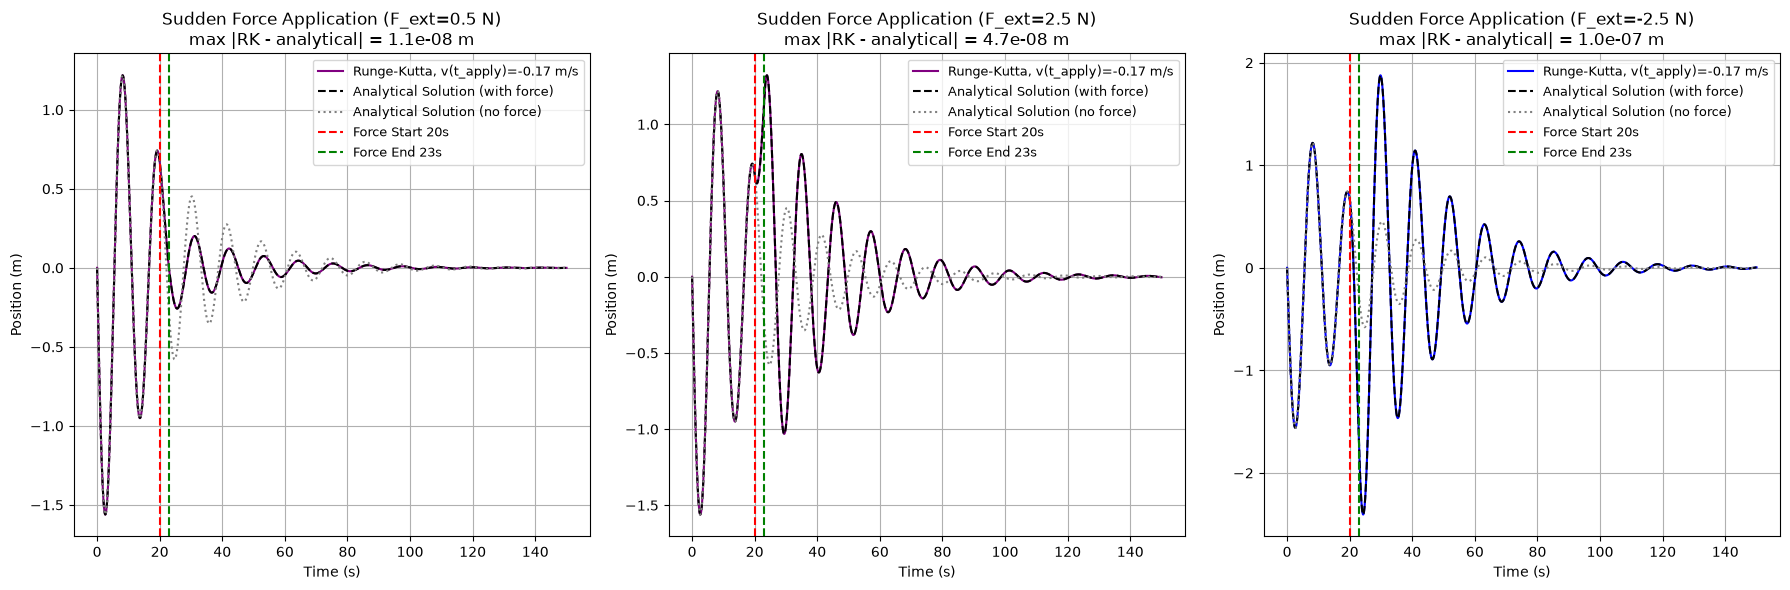

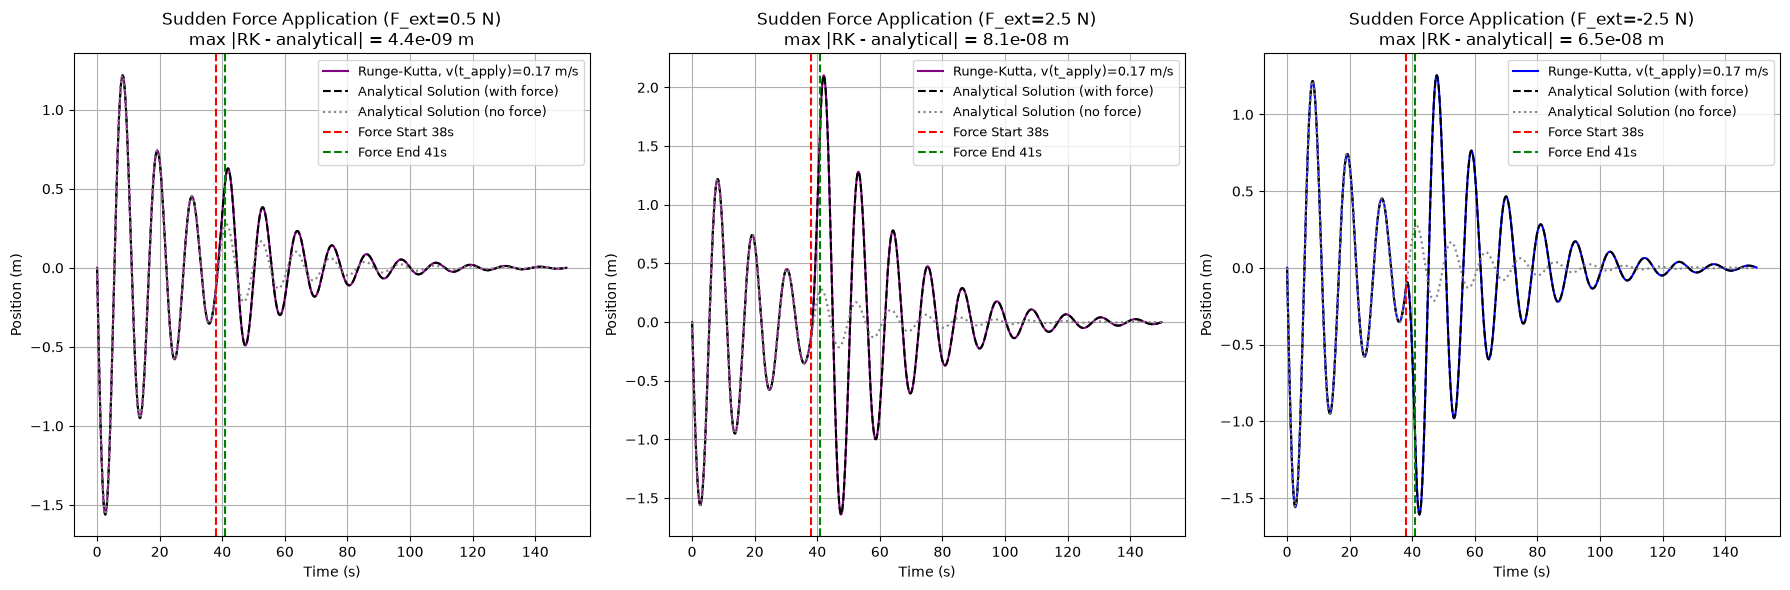

In [16]:
# Sudden force function
def sudden_force(t, F_ext, t_apply, duration):
    """
    Sudden force "push", that can be applied on the system for certain duration.
    """
    if t_apply <= t < t_apply + duration:
        return F_ext
    else:
        return 0

# Function that finds velocity at the time of force application
def get_velocity_at_t_apply(t, v, t_apply):
    """
    This function finds velocity value at the time of the sudden force application.
    """
    # Find the index where the time is closest to t_apply
    idx = (np.abs(t - t_apply)).argmin()
    return v[idx]

# Plotting function
def plot_sudden_force_applications(x0, v0, hstep, nsteps, b, F_ext_range, applied_time):
    """
    Plotting for sudden force application.
    """
    # Adjust figure size
    plt.figure(figsize=(18, 6))

    #Iterate through external forces
    for i, F_ext in enumerate(F_ext_range, start=1):
        plt.subplot(1, len(F_ext_range), i)
        force_params = {'F_ext': F_ext, 't_apply': applied_time, 'duration': duration}

        # Call Runge-Kutta Method (max_step makes sure the solver sees the pulse)
        t, x, v = RungeKuttaDrivingForce(x0, v0, nsteps, hstep, sudden_force, force_params, b, max_step=duration / 10)
        x_exact = AnalyticSuddenForce(x0, v0, t, b, F_ext, applied_time, duration)
        max_error = np.max(np.abs(x - x_exact))

        # Search velocity at applied time
        velocity_at_application = get_velocity_at_t_apply(t, v, applied_time)

        # Define colours depending on the sign of eternal force: purple is positive, blue is negative
        color = 'purple' if F_ext > 0 else 'blue'

        # Plot Runge_Kutta Method
        plt.plot(t, x, label=f'Runge-Kutta, v(t_apply)={velocity_at_application:.2f} m/s', color=color)

        # Analytical solution with the force, and without it for comparison
        plt.plot(t, x_exact, 'k--', label='Analytical Solution (with force)')
        plt.plot(t, analytic_solution(x0, v0, t, b), color='grey', linestyle=':', label='Analytical Solution (no force)')

        # Vertical lines that shows time of application and its duration
        plt.axvline(x=applied_time, color='red', linestyle='--', label=f'Force Start {applied_time:.3g}s')
        plt.axvline(x=applied_time + duration, color='green', linestyle='--', label=f'Force End {applied_time + duration:.3g}s')

        # Title and labels
        plt.title(f'Sudden Force Application (F_ext={F_ext} N)\nmax |RK - analytical| = {max_error:.1e} m')
        plt.xlabel('Time (s)')
        plt.ylabel('Position (m)')
        plt.legend(fontsize=9)
        plt.grid(True)

    plt.tight_layout()
    plt.show()


# Call function for plotting
plot_sudden_force_applications(x0, v0, h[2], nsteps, b[1], F_ext, t_apply)
plot_sudden_force_applications(x0, v0, h[2], nsteps, b[1], F_ext, t_apply2)

### Sinusoidal Force and its plotting

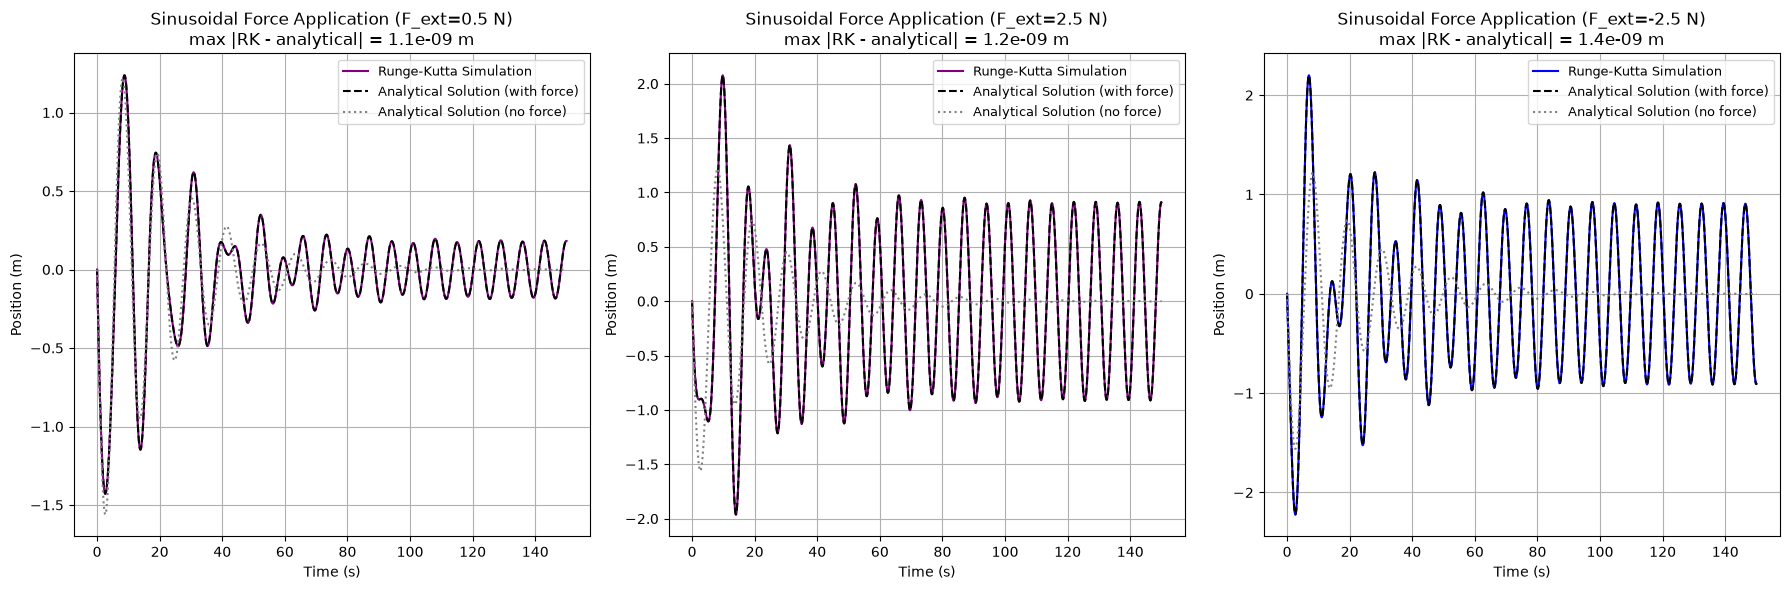

In [17]:
def sinusoidal_force(t, F_ext, omega_ext, phi=0):
    """
    The sinusoidal force that drives the system throughout.
    """
    return F_ext * np.cos(omega_ext * t + phi)

def plot_sinusoidal_force_applications(x0, v0, hstep, nsteps, b, F_ext_range):
    """
    Plotting for the sinusoidal force.
    """
    # Adjust the size of the figure
    plt.figure(figsize=(18, 6))

    # Iteration through the external force array
    for i, F_ext in enumerate(F_ext_range, start=1):
        plt.subplot(1, len(F_ext_range), i)
        force_params = {'F_ext': F_ext, 'omega_ext': omega_ext, 'phi': phi}

        # Call Runge-Kutta method
        t, x, _ = RungeKuttaDrivingForce(x0, v0, nsteps, hstep, sinusoidal_force, force_params, b)
        x_exact = AnalyticSinusoidalForce(x0, v0, t, b, F_ext, omega_ext, phi)
        max_error = np.max(np.abs(x - x_exact))

        # Define colours depending on the sign of eternal force: purple is positive, blue is negative
        color = 'purple' if F_ext > 0 else 'blue'

        # Plot Runge_Kutta Method
        plt.plot(t, x, color=color, label='Runge-Kutta Simulation')

        # Analytical solution with the force, and without it for comparison
        plt.plot(t, x_exact, 'k--', label='Analytical Solution (with force)')
        plt.plot(t, analytic_solution(x0, v0, t, b), color='grey', linestyle=':', label='Analytical Solution (no force)')

        # Title and labels
        plt.title(f'Sinusoidal Force Application (F_ext={F_ext} N)\nmax |RK - analytical| = {max_error:.1e} m')
        plt.xlabel('Time (s)')
        plt.ylabel('Position (m)')
        plt.legend(fontsize=9)
        plt.grid(True)

    plt.tight_layout()
    plt.show()

# Call function for plotting
plot_sinusoidal_force_applications(x0, v0, h[2], nsteps, b[1], F_ext)

### Observation notes 9

In every case the Runge-Kutta solution agrees with the exact analytical solution of the driven system to about $10^{-7}$ m or better (the maximum difference is shown in each title), so the curves below are accurate.

#### Sudden Force:
##### Effect of velocity and force directions:
When analyzing the impact of force direction relative to the system's velocity, an external force of magnitude $\pm2.5$ N was applied at two distinct times—20 and 38 seconds—to observe the system's response when the velocity is positive or negative. In the scenarios depicted by the first two graphs, the system has a negative velocity of $-0.17$ m/s at the time of force application.

When a positive force is applied to the system while it has a negative velocity, it acts in opposition to the motion. This opposition temporarily reduces the kinetic energy, decelerating the mass. As a result, the mass changes direction, moving towards the positive axis until the application of force discontinues. The duration of this force is critical; for example, a force applied for 3 seconds against the direction of velocity induces a phase shift of approximately $\pi$ radians, or 180 degrees, relative to the motion without the force. Such a phase shift significantly alters the mass-spring system's oscillatory behaviour, illustrating the profound influence of an opposing force.

In contrast, when a negative force coincides with negative velocity, the direction of motion—and consequently, the phase—remains consistent, as the kinetic energy increases, amplifying the system's amplitude. This increase occurs because the force reinforces the direction of velocity, effectively adding energy to the system and enhancing its oscillatory motion.

This principle is mirrored under reversed circumstances, at a different time, demonstrating that the interplay between the direction of applied force and the system's instantaneous velocity governs the energy transfer within the system—constraining or enhancing the amplitude of oscillation accordingly.

#### Sinusoidal Force:
In the first periods of oscillation, the free (transient) part of the solution and the forced part add up to an irregular pattern. The transient decays with time constant $2m/b \approx 22$ s, and after roughly $100$ seconds the system settles into the steady-state response: oscillations at the driving frequency with amplitude $F_{ext}/\sqrt{(k-m\omega^2)^2+(b\omega)^2}$, which is $0.18$ m for $0.5$ N and $0.91$ m for $2.5$ N.

Applying a negative instead of a positive force reverses the sign of the steady-state response (a phase shift of $\pi$), but its amplitude is the same.

### Further investigation of sinusoidal force for: low, natural, high frequency
#### Natural Frequency: 
Every oscillating system has one or more natural frequencies, which are the frequencies at which the system tends to vibrate when not subjected to an external force or when it returns to oscillating freely after being disturbed.
We can determine natural frequency of the system using following equation

$$\omega_n = \sqrt{\frac{k}{m}}$$

we also defined low frequency to be $0.1\omega_n$ and high frequency as $6.0\omega_n$. 

This part of experiment aims to investigate phenomenon of resonance. The parameters are used as described in previous part.

#### Resonance:
Resonance occurs in a system when it is exposed to an oscillating external force or a periodic disturbance at a frequency that matches the system's natural frequency of vibration. This condition leads to a significant increase in the amplitude of the system's oscillations.

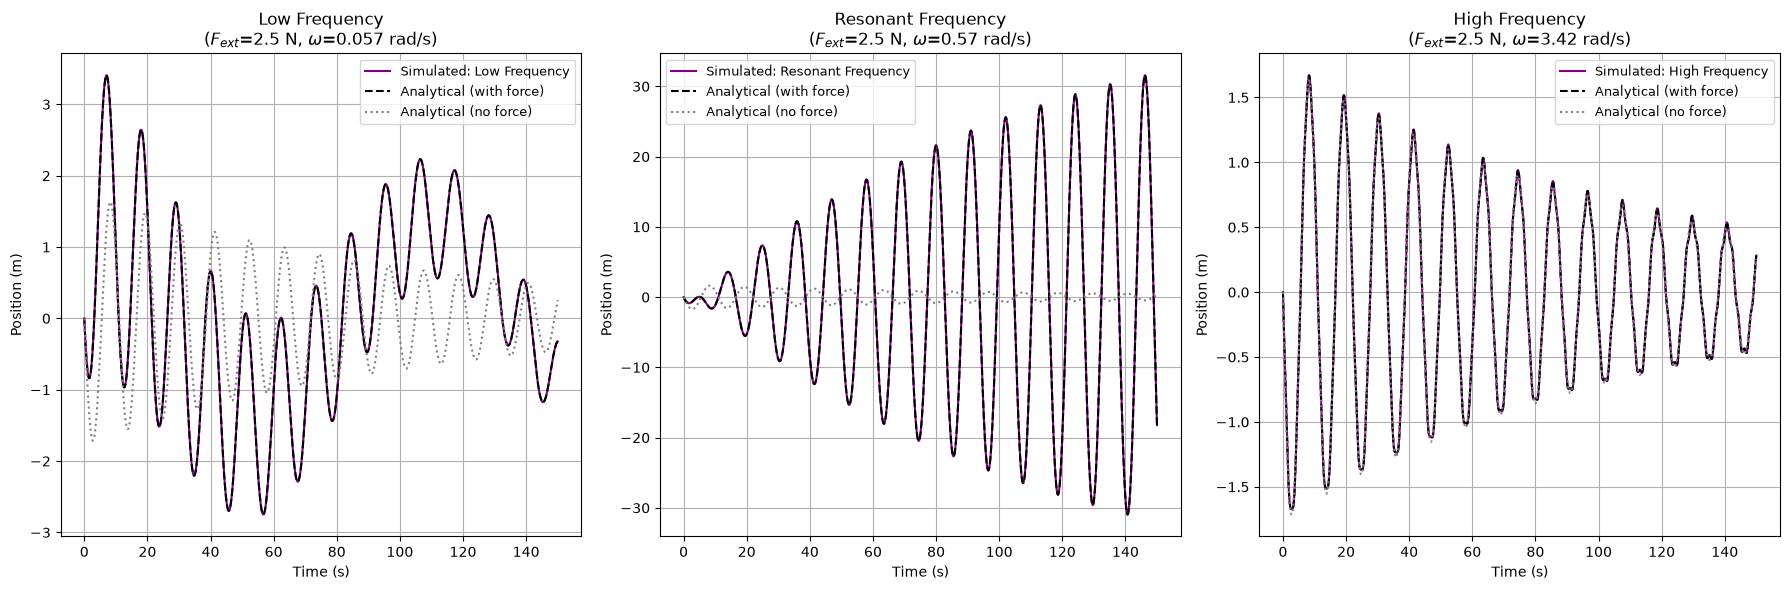

In [18]:
omega_n = np.sqrt(k / m)  # Natural frequency of the system

# Angular frequencies for the external force
omega_list = [
    (0.1 * omega_n, "Low Frequency"),
    (omega_n, "Resonant Frequency"),
    (6.0 * omega_n, "High Frequency")
]

def plot_driving_force_responses(omega_list, nsteps, hstep, b):
    """
    This is plotting function for the driving force responses
    considering three values of angular frequency: low, resonant, and high.
    """
    # Adjusting size of the figure
    plt.figure(figsize=(18, 6))

    # Iteration through values of angular frequency
    for i, (omega_drive, description) in enumerate(omega_list, start=1):

        # Run simulation with the specified driving force frequency
        t, x_sinusoidal, _ = RungeKuttaDrivingForce(x0, v0, nsteps, hstep, sinusoidal_force,
                                                    {'F_ext': F_ext[1], 'omega_ext': omega_drive}, b)
        x_exact = AnalyticSinusoidalForce(x0, v0, t, b, F_ext[1], omega_drive)

        # Plot simulation results
        plt.subplot(1, len(omega_list), i)
        plt.plot(t, x_sinusoidal, label=f'Simulated: {description}', color='purple')

        # Plot analytical results with and without the force
        plt.plot(t, x_exact, label='Analytical (with force)', linestyle='--', color='black')
        plt.plot(t, analytic_solution(x0, v0, t, b), label='Analytical (no force)', linestyle=':', color='grey')

        # Title and labels
        plt.title(f'{description}\n($F_{{ext}}$={F_ext[1]:.3g} N, $\\omega$={omega_drive:.3g} rad/s)')
        plt.xlabel('Time (s)')
        plt.ylabel('Position (m)')
        plt.legend(fontsize=9)
        plt.grid(True)

    plt.tight_layout()
    plt.show()

# Call function for plotting
plot_driving_force_responses(omega_list, nsteps, h[2], b[0])

### Observation notes 10
The dashed line is the exact solution with the driving force and the dotted line the free oscillation of the system without an external force, showing a decaying amplitude at the system's own natural frequency. The simulated and exact forced solutions coincide.

#### Low frequency:
$\omega = 0.057$ rad/s

The response is the sum of the slow forced motion and the decaying free oscillation at the natural frequency. The slow part follows the force almost in phase, with amplitude close to the static displacement $F_{ext}/k \approx 1.4$ m.

#### Resonant frequency:
$\omega_n = 0.57$ rad/s

At the resonant frequency, the system exhibits a large increase in the amplitude of oscillations, a hallmark of resonance. The energy from the sinusoidal force is being transferred into the system most effectively. With $b=0.1$ kg/s the amplitude is still growing at the end of the 150 s run, because the decay time $2m/b \approx 112$ s is comparable to the run length; it approaches the steady-state value $F_{ext}/(b\omega_n) \approx 44$ m, about 25 times the initial amplitude of the free oscillation.

#### High frequency:
$\omega = 3.42$ rad/s

At high driving frequencies, the system's response closely follows the free oscillation, with a small, fast ripple at the driving frequency on top. The steady-state amplitude is only $F_{ext}/\sqrt{(k-m\omega^2)^2+(b\omega)^2} \approx 0.04$ m, so the system is largely unaffected when the driving frequency is six times its natural frequency.

### Further analysis of the resonance

The resonance can be investigated further by plotting the steady-state amplitude against a range of angular frequencies. Aims of this plotting is to observe the peak of the resonant curve under different values of damping. We will use damping coefficients: $0.1$, $0.5$, $2.0$ kg/s.

The lines are the analytical steady-state amplitude $A(\omega) = F_{ext}/\sqrt{(k-m\omega^2)^2+(b\omega)^2}$, whose peak lies at $\omega_r = \sqrt{\omega_n^2 - b^2/2m^2}$. The circles are measured from Runge-Kutta runs of 600 s as the largest $|x|$ over the last quarter of the run, when the transient has decayed (for $b=0.1$ kg/s the decay time is about 112 s).

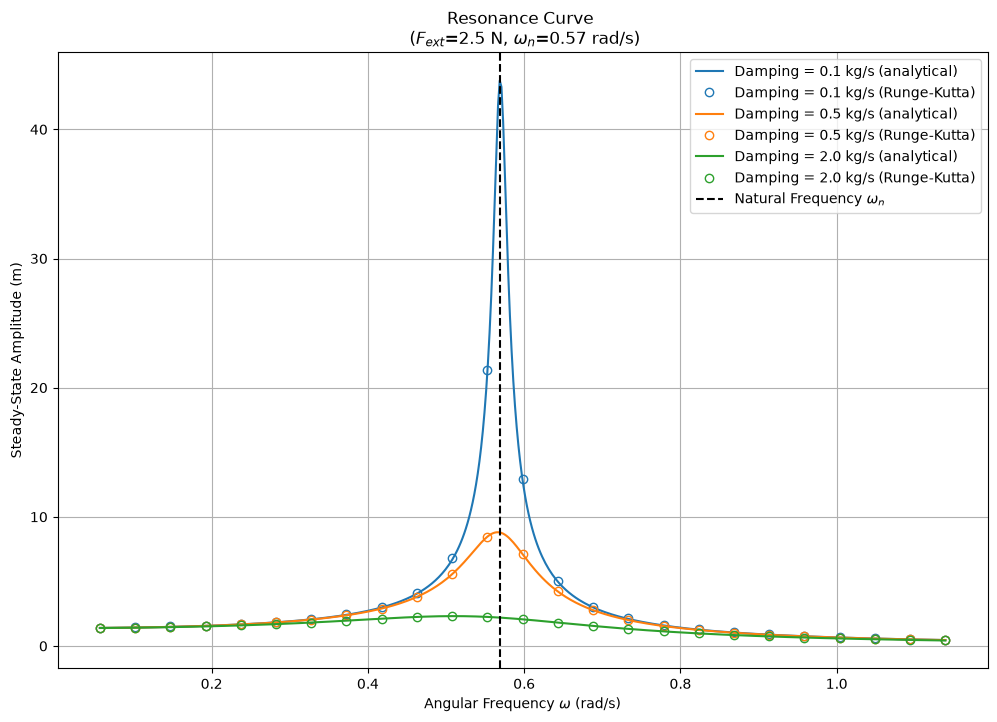

b = 0.1 kg/s: peak at omega = 0.569 rad/s, peak amplitude = 43.9 m
b = 0.5 kg/s: peak at omega = 0.566 rad/s, peak amplitude = 8.81 m
b = 2.0 kg/s: peak at omega = 0.510 rad/s, peak amplitude = 2.31 m


In [19]:
def measure_steady_state_amplitude(omega_drive, F_ext, b, T_run, hstep):
    """
    Runs Runge-Kutta for T_run seconds and returns the largest |x| over the last quarter of the run,
    i.e. after the start-up transient has decayed (T_run should be several decay times 2m/b).
    """
    nsteps, t = time_grid(T_run, hstep)
    _, x, _ = RungeKuttaDrivingForce(x0, v0, nsteps, hstep, sinusoidal_force,
                                     {'F_ext': F_ext, 'omega_ext': omega_drive}, b)
    return np.max(np.abs(x[t >= 0.75 * T_run]))

def plot_resonance_curve(omega_n, omega_range, F_ext, b_values, n_numeric=25, T_run=600, hstep=0.05):
    """
    This is plotting function of resonance curve: steady-state amplitude vs. angular frequency.
    Lines are the analytical steady-state amplitude, circles are measured from Runge-Kutta runs.
    """
    # Adjusting size of the figure
    plt.figure(figsize=(12, 8))

    # Range of omega values
    omega_fine = np.linspace(omega_range[0] * omega_n, omega_range[1] * omega_n, 500)
    omega_numeric = np.linspace(omega_range[0] * omega_n, omega_range[1] * omega_n, n_numeric)

    # Iteration through damping coefficients
    for j, b_val in enumerate(b_values):
        color = f'C{j}'
        plt.plot(omega_fine, steady_state_amplitude(F_ext, omega_fine, b_val), color=color,
                 label=f'Damping = {b_val} kg/s (analytical)')
        amplitudes = [measure_steady_state_amplitude(w, F_ext, b_val, T_run, hstep) for w in omega_numeric]
        plt.plot(omega_numeric, amplitudes, 'o', color=color, markerfacecolor='none',
                 label=f'Damping = {b_val} kg/s (Runge-Kutta)')

    # Vertical line at natural frequency
    plt.axvline(x=omega_n, color='k', linestyle='--', label=r'Natural Frequency $\omega_n$')

    # Title and labels
    plt.xlabel(r'Angular Frequency $\omega$ (rad/s)')
    plt.ylabel('Steady-State Amplitude (m)')
    plt.title(f'Resonance Curve \n ($F_{{ext}}$={F_ext:.3g} N, $\\omega_n$={omega_n:.3g} rad/s)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Peak positions and heights from the analytical curve
    for b_val in b_values:
        w_peak = np.sqrt(max(omega_n**2 - b_val**2 / (2 * m**2), 0))
        print(f"b = {b_val} kg/s: peak at omega = {w_peak:.3f} rad/s, "
              f"peak amplitude = {steady_state_amplitude(F_ext, w_peak, b_val):.3g} m")

# Call function for plotting
plot_resonance_curve(omega_n, (0.1, 2), F_ext[1], b)

### Observation notes 11

The dashed vertical line represents the natural frequency of the system ($\omega_n=0.57$ rad/s). The amplitudes measured from the simulations agree with the analytical steady-state curves.

The curve with the lowest damping (0.1 kg/s) has the highest and narrowest peak ($43.9$ m), at $\omega_r=0.569$ rad/s, practically at the natural frequency. As the damping increases, the peaks become lower and broader ($8.81$ m for $b=0.5$ kg/s and $2.31$ m for $b=2.0$ kg/s), indicating that more energy is dissipated per cycle.

The frequency of the largest amplitude moves to lower frequencies as the damping increases ($0.566$ rad/s for $b=0.5$ kg/s and $0.510$ rad/s for $b=2.0$ kg/s), as given by $\omega_r = \sqrt{\omega_n^2 - b^2/2m^2}$.

Away from the resonant frequency, the amplitudes of oscillations are small for all damping levels: at low frequencies they approach the static displacement $F_{ext}/k \approx 1.4$ m, and at high frequencies they fall towards zero.

### Quality factor

The quality factor $Q$ of a damped harmonic oscillator is a dimensionless parameter that describes the damping of the system. It is defined as the ratio of the peak energy stored in the system to the energy lost per cycle at resonance. For a mass-spring damped system it can be calculated using the formula:

$$Q = \frac{1}{2\zeta} = \frac{m\omega_0}{b}$$

where $\zeta$ is the damping ratio, $m$ is mass, $b$ is the damping coefficient, and $omega_0$ is the natural frequency of the system defined in previous part of the experiment.

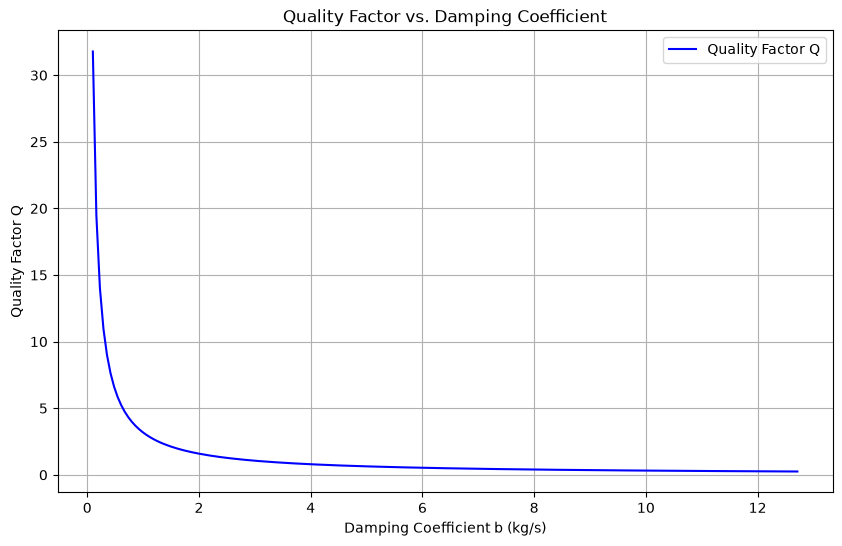

In [20]:
# Determine the array of damping coefficients between 0.1 and double critical value
dampings = np.linspace(0.1, b_double, 200)

# Quality factor function
def Qfactor(omega_n, m, b):
    """
    This function determines the quality factor of the system.
    """
    # Damping ratios for each damping
    damping_ratios = b / (2 * m * omega_n)

    # Quality factors for each damping
    quality_factors = 1 / (2 * damping_ratios)

    return quality_factors

# Plot the quality factor as a function of the damping coefficient
def plot_Qfactor(b, q_factor):
    """
    Plotting the Quality factor against the damping coefficients.
    """
    # Adjust size of the figure
    plt.figure(figsize=(10, 6))

    # Plot
    plt.plot(b, q_factor, 'b-', label='Quality Factor Q')

    # Title and labels
    plt.xlabel('Damping Coefficient b (kg/s)')
    plt.ylabel('Quality Factor Q')
    plt.title('Quality Factor vs. Damping Coefficient')

    # Legend and grid
    plt.legend()
    plt.grid(True)
    plt.show()

plot_Qfactor(dampings, Qfactor(omega_n, m, dampings))

### Observation notes 12

The quality factor, or Q-factor, is inversely proportional to the damping coefficient; as the damping increases, the system's quality factor approaches zero. Conversely, with low damping, the quality factor rises, reaching a peak value of approximately 31.8. The Q-factor provides insight into the resonance peak's "sharpness": high Q-factors correspond to low damping and a sharply defined peak, while low Q-factors are indicative of higher damping, resulting in broader resonance peaks, as was observed in previous experiments.

### Conclusion
This study analyzed the performance of several numerical integration methods: Euler's, Improved Euler's, Euler-Cromer's, Verlet's, Runge-Kutta 4 and SciPy's adaptive Runge-Kutta 45, applied to a damped mass-spring system and compared with the analytical solutions on a common time grid.

The measured orders of accuracy agree with theory: Euler, Improved Euler and Euler-Cromer are first order, Verlet is second order and Runge-Kutta 4 is fourth order. Runge-Kutta 4 was the most accurate method in every scenario, for all damping coefficients (underdamped, critical and heavily damped) and all step sizes, typically by several orders of magnitude. Verlet's method was the second-best fixed-step method. The accuracy of SciPy's RK45 is set by its tolerances rather than by the step size, so it is a convenient but not a step-size-controlled method. Euler and Improved Euler gain energy relative to the physical system for light damping and large steps, while Euler-Cromer's energy oscillates about the true value.

The experiment further explored the system's response to sudden and sinusoidal driving forces, using the exact solutions of the driven system to confirm the simulations. A force applied against the direction of motion shifts the phase of the oscillation relative to the undriven motion, while a force aligned with the motion increases the amplitude without changing the phase. Under sinusoidal driving the system settles into a steady-state oscillation at the driving frequency.

Additionally, the concept of resonance was examined, showing that low damping leads to higher quality factors and sharper resonance peaks close to the natural frequency, while increased damping gives a lower quality factor and broader, lower peaks at slightly lower frequencies, indicating more energy dissipation.

In conclusion, the study demonstrated the comparative effectiveness of numerical methods in predicting the behavior of damped oscillatory systems: for this problem the fixed-step Runge-Kutta 4 gives the best accuracy for a given step size, and the critical impact of damping on resonance was shown.